# After the World Fell Silent: The Rise, Collapse and Unfinished Comeback of Philippine Tourism
*Philippine Tourism Trends by Market, 2008–2024*

**DS311 Exploratory Data Analysis · Midterm Lab Exam · Group 6 (Culture and Tourism)**

**Members:** Aque, Badilla, Beturin, Dellosa, Ganhinhin, Pamplona, Ruiz

| Section | Focus |
|---|---|
| 1–2 | Business question, data source and variables |
| 3 | Data extraction from PDF, cleaning and quality checks |
| 4 | Univariate analysis I: distributions |
| 5 | Univariate analysis II: growth and recovery, remaining gap, composition, seasonality |
| 6.1–6.2 | Bivariate: correlation matrices, Korea vs China regression |
| 6.3–6.4 | Bivariate: correlation by period, rolling correlation |
| 7 | Conclusions, recommendations, limitations |

## Introduction

**Why tourism numbers matter.** Behind every international arrival in the Philippines is a booked flight, an occupied hotel room, a hired guide and a meal bought from a local business. Visitor arrivals are therefore more than a head count. They show how connected the country is to the rest of the world, and which parts of the world are most connected to it. For the Department of Tourism (DOT), and for the many businesses that depend on visitors, knowing where arrivals come from is just as important as knowing how many there are.

**The story in the data.** From 2008 to 2019, the story was one of steady growth. Yearly arrivals rose from about 3.1 million to 8.3 million, an average of 9.2% a year, with only one small dip during the 2009 global financial crisis. Then, in early 2020, travel almost stopped. Monthly arrivals fell from 796,164 in January 2020 to just 948 in April 2020. Borders reopened slowly, and by 2024 the country recorded 5.9 million arrivals, about 72% of the 2019 level. The recovery is real, but it is unfinished, and it has not been shared equally. Some source markets returned quickly, while China, one of the largest sources before the pandemic, has returned far more slowly.

**What this notebook does.** Our only source is the DOT's own visitor-arrival statistics: 17 yearly PDF reports covering January 2008 to December 2024. Because the tables sit inside PDFs and their layouts change over the years, a large part of the work is reading them correctly, checking them against the totals printed in the reports, and building one consistent dataset of 50 source markets over 201 months with data. From this dataset we describe how monthly arrivals are distributed, measure growth and recovery, identify which markets account for the remaining gap to 2019, look for seasonal patterns, and study how markets move in relation to one another.

**A caution that runs through the analysis.** When many series rise together, they look closely related even if they have little else in common. A shared upward trend is easily mistaken for a genuine link between markets. For this reason, whenever we find a strong relationship, we test whether it still holds once the shared trend is removed.

**How to read this notebook.** No special background is needed. Most steps pair the code with a short written interpretation, so the findings can be followed without reading the code. Section 1 states the problem and the questions we ask. Sections 2 and 3 describe and prepare the data. Sections 4 to 6 analyse it, and Section 7 gives the conclusions, recommendations and limitations.

## 1. Problem statement

For more than a decade, the planning question in Philippine tourism was simple: how do we welcome more visitors? The data gave a reassuring answer, because arrivals rose almost every year until 2019. The pandemic changed the question. Arrivals collapsed, and although they have been climbing back, the 2024 total is still below the 2019 level. A single national total can no longer guide decisions, because it hides which source markets are still missing and which have already returned.

This creates a practical problem for tourism planners. If they cannot tell which markets drove growth, how far each one has recovered and when visitors tend to arrive, promotion efforts may be aimed at the wrong markets or the wrong months. There is a second risk. Because most markets were growing at the same time, they can appear to move together when they are only riding the same wave, which leads to false conclusions about how one market relates to another.

This notebook uses the DOT's visitor-arrival statistics to address that problem. Its central question is the business question below, which we break down into four sub-questions.

### Business Question
**How fast has international tourism to the Philippines grown since 2008, which source markets drove that growth, and how did COVID-19 change the way markets move relative to each other?**

Sub-questions
1. How are monthly arrivals distributed (centre, spread, shape, outliers)?
2. How fast did total and market arrivals grow before COVID-19, and how much had been recovered by 2023 and 2024?
3. Which markets account for the remaining gap to 2019, and is there a seasonal pattern?
4. How strongly are two markets' monthly arrivals related (two numerical variables), and is that relationship real or just a shared trend?

## 2. Data
- **Source:** Philippine Department of Tourism (DOT) visitor-arrival statistics (https://remote.tourism.gov.ph/tourism/demand-statistics/), stored in our repository as the **17 original DOT PDF reports** `data/raw/2008.pdf` … `data/raw/2024.pdf` (https://github.com/Ajooooooo/EDA-Group-6). No pre-compiled spreadsheet is used: the notebook reads the tables directly from the PDFs.
- **Unit:** one row per month and source market. After extraction the panel covers **January 2008 to December 2024 (204 calendar months)**, of which 201 have data (Section 3.4).
- **Variables used:** monthly arrivals per market (numerical); the DOT grand total (numerical); region and period (categorical).
- **Definition note:** the 2008–2023 tables list *foreign visitors by country of residence* and report **Philippine-passport holders living abroad ("Overseas Filipinos") on a separate row**; the grand total includes them. The 2022 table is by nationality, and the 2024 table has no separate overseas-Filipino row. These differences matter for comparisons and are examined in Section 3.4.
- **Files produced by this notebook:** `data/processed/data_cleaned.xlsx` (long format: month × market) and `data/processed/data_monthly_summary.xlsx` (one row per calendar month).

In [6]:
import re, warnings
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
import pdfplumber
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.stattools import durbin_watson
from IPython.display import display
warnings.filterwarnings('ignore')
PAL={'teal':'#0B6E8A','orange':'#F2A33A','red':'#D9534F','green':'#5B8C5A','purple':'#7A6C9D'}
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi']=100
pd.options.display.float_format='{:,.2f}'.format

def corr_ci(r,n,alpha=0.05):
    """Fisher z confidence interval for a Pearson correlation."""
    z=np.arctanh(r); se=1/np.sqrt(n-3); k=stats.norm.ppf(1-alpha/2)
    return np.tanh(z-k*se), np.tanh(z+k*se)

def cagr(a,b,years): return (b/a)**(1/years)-1

# Locate the repository root whether the notebook is run from notebooks/ or from the repo root
def find_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        for cand in (base, base/'philippine-tourism-data-analysis'):
            if (cand/'data'/'raw').exists(): return cand
    raise FileNotFoundError('data/raw not found - run the notebook from inside the repository')
ROOT=find_root(); RAW=ROOT/'data'/'raw'; OUT=ROOT/'data'/'processed'; OUT.mkdir(parents=True,exist_ok=True)
print('Repository root:',ROOT)
print('PDF files found:',len(list(RAW.glob('*.pdf'))))

Repository root: d:\Ganhinhin USTP\3rd yr\1st sem\EDA\Midterm PIT By Group\philippine-tourism-data-analysis
PDF files found: 17


## 3. Data extraction and quality checks
The raw data are PDF reports, so the first job is to read the tables reliably. We (a) inventory the layouts, (b) extract every table, (c) prove that the extraction is correct by reconciling it with the totals printed in the PDFs, (d) build one consistent market panel, and (e) check gaps, placeholders and definition changes.

In [7]:
inv=pd.DataFrame([
 ['2008-2021','14 PDFs, 3 pages each','Visitor arrivals by country of residence','Jan-Dec','Foreign visitors by country + separate "Overseas Filipinos" row; grand total printed'],
 ['2022','1 PDF, 4 pages','AIR visitor arrivals by nationality','Feb-Dec (no January)','Nationality basis, air arrivals only; 233 nationalities'],
 ['2023','1 PDF, 12 pages','Ranking by country of residence (+ a second table by nationality)','Jan-Oct (no Nov, Dec)','Residence basis; ~240 countries; overseas Filipinos separate'],
 ['2024','1 PDF, 2 pages','Top-60 markets: one table by citizenship, one by residence','Jan-Dec','Residence table: 60 markets + "others"; no overseas-Filipino row'],
],columns=['years','files','what the table is','months covered','notes'])
display(inv)

,years,files,what the table is,months covered,notes
0,2008-2021,"14 PDFs, 3 pages each",Visitor arrivals by country of residence,Jan-Dec,"Foreign visitors by country + separate ""Overse..."
1,2022,"1 PDF, 4 pages",AIR visitor arrivals by nationality,Feb-Dec (no January),"Nationality basis, air arrivals only; 233 nati..."
2,2023,"1 PDF, 12 pages",Ranking by country of residence (+ a second ta...,"Jan-Oct (no Nov, Dec)",Residence basis; ~240 countries; overseas Fili...
3,2024,"1 PDF, 2 pages","Top-60 markets: one table by citizenship, one ...",Jan-Dec,"Residence table: 60 markets + ""others""; no ove..."


**Finding 1 – four different table layouts.** The 2008–2021 reports share one layout. 2022, 2023 and 2024 each differ in what is measured (residence vs nationality), which months are present and how many markets are listed. A single `read_csv` would not work; each layout needs its own reader, and the results must be harmonised before any analysis.

### 3.1 Reading the PDFs
The PDF text layer splits some numbers (for example `179,900` is returned as `1` and `79,900`), which would silently corrupt the data. The reader therefore rebuilds each line from individual characters and only starts a new value after a visible gap.

In [8]:
# ---------- PDF reading helpers ----------
# pdfplumber's default word splitter breaks some numbers ("179,900" -> "1" + "79,900") in these PDFs,
# so each text line is rebuilt from individual characters: a new token starts only after a visible gap.
NUM=r"(?:\(?-?[\d,]+(?:\.\d+)?%?\)?\**|-)"
NAME=r"[A-Za-z][A-Za-z0-9 .,'&/()*\-]*?"
def tonum(t):
    t=t.strip().rstrip('*').rstrip('%')
    if t=='-': return np.nan                      # DOT's dash = no recorded arrivals (handled in 3.4)
    t=t.replace(',','')
    return -float(t[1:-1]) if t.startswith('(') and t.endswith(')') else float(t)

def page_lines(page,ytol=2.0):
    chars=sorted([c for c in page.chars if c['text'].strip()],key=lambda c:(c['top'],c['x0']))
    rows=[]
    for c in chars:
        if rows and abs(c['top']-rows[-1][0])<=ytol: rows[-1][1].append(c)
        else: rows.append([c['top'],[c]])
    out=[]
    for _,cs in rows:
        cs.sort(key=lambda c:c['x0']); s=cs[0]['text']
        for p,c in zip(cs,cs[1:]): s+=(' ' if c['x0']-p['x1']>0.15*c['size'] else '')+c['text']
        out.append(s)
    return out

def pdf_lines(year):
    with pdfplumber.open(RAW/f'{year}.pdf') as pdf:
        for pn,page in enumerate(pdf.pages,1):
            for l in page_lines(page): yield pn,l.strip()

re_plain=re.compile(rf"^(?P<name>{NAME})\s+(?P<nums>{NUM}(?:\s+{NUM})+)\s*$")
re_mtot =re.compile(rf"^(?P<name>\d{{4}} MONTHLY TOTAL)\s+(?P<nums>{NUM}(?:\s+{NUM})+)\s*$")
re_rank =re.compile(rf"^(?P<rank>\d+\.?|\*)\s+(?P<name>[A-Za-z*][A-Za-z0-9 .,'&/()*\-]*?)\s+(?P<nums>{NUM}(?:\s+{NUM})+)\s*$")

# Rows of the 2008-2021 tables that are not countries
SPECIAL={'SUB-TOTAL','TOTAL','T O T A L','TOTAL (CIS & RUSSIA)','RESIDENCES','OVERSEAS FILIPINOS',
         'INDEPENDENT STATES','MONTENEGRO, REP','SERBIA, REP','MONTENEGRO)','GRAND'}

def parse_0821(y):
    """2008-2021: 'by country of residence', one row per country, 12 monthly columns."""
    d={}
    for _,l in pdf_lines(y):
        m=re_mtot.match(l) or re_plain.match(l)
        if not m: continue
        t=m['nums'].split()
        if len(t)<12: continue
        nm=m['name'].rstrip('* ').strip()
        if nm.startswith('Monthly'): continue
        if nm.endswith('MONTHLY TOTAL'):
            if not nm.startswith(str(y)): continue      # the page also shows last year's total
            nm='GRAND'
        d.setdefault(nm,[]).append([tonum(x) for x in t[:12]])
    return d

def parse_rank(y,marker,nm):
    """2022-2024: ranked tables (rank, country, monthly columns...). Returns (country rows, summary rows)."""
    rows={}; sp={}; sect=''
    for _,l in pdf_lines(y):
        if 'RANKING BY' in l.upper(): sect=l.upper()
        if y!=2022 and marker not in sect: continue
        l1=re.sub(r'^\*\s+(?=[A-Za-z])','',l)
        m=re_rank.match(l)
        if m and m['rank']!='*':
            t=m['nums'].split()
            if len(t)>=nm: rows[m['name'].strip()]=[tonum(x) for x in t[:nm]]
            continue
        m=re_plain.match(l1)
        if m:
            k=m['name'].strip().rstrip('* ').upper(); t=m['nums'].split()
            if k in ('GRAND TOTAL','OVERSEAS FILIPINOS','TOTAL OVERSEAS FILIPINOS','FOREIGN TOURISTS','TOTAL FOREIGN TOURIST') and len(t)>=nm:
                sp[k]=[tonum(x) for x in t[:nm]]
        m=re_rank.match(l)
        if m and m['rank']=='*' and 'OTHER' in m['name'].upper(): sp['OTHERS']=[tonum(x) for x in m['nums'].split()[:nm]]
    return rows,sp

P={y:parse_0821(y) for y in range(2008,2022)}
R22,S22=parse_rank(2022,'',11)                          # Feb-Dec 2022, air arrivals by nationality
R23,S23=parse_rank(2023,'COUNTRY OF RESIDENCE',10)      # Jan-Oct 2023, by country of residence
R24,S24=parse_rank(2024,'COUNTRY OF RESIDENCE',12)      # Jan-Dec 2024, top-60 markets by residence
FY23=parse_rank(2024,'COUNTRY OF RESIDENCE',15)[1]['GRAND TOTAL'][14]   # full-year 2023 total printed in the 2024 table
print('Parsed rows  2008-2021:',sum(len(v) for v in P.values()),'| 2022:',len(R22),'| 2023:',len(R23),'| 2024:',len(R24))
print(f'Full-year 2023 grand total printed in the 2024 PDF: {FY23:,.0f}')

Parsed rows  2008-2021: 1005 | 2022: 233 | 2023: 242 | 2024: 60
Full-year 2023 grand total printed in the 2024 PDF: 5,450,557


### 3.2 Reconciliation: does the extraction add up?
Each PDF prints subtotals and a grand total. If the extracted country rows sum to those printed figures, the extraction is correct.

In [9]:
# Does every parsed table add up to the totals printed in the same PDF?
aud=[]
for y in range(2008,2022):
    d=P[y]; keys=[k for k in d if k not in SPECIAL]
    s=np.nansum([d[k][0] for k in keys],axis=0)
    tot=np.array(d.get('T O T A L',d.get('TOTAL'))[0]); of=np.nan_to_num(np.array(d['OVERSEAS FILIPINOS'][0])); gr=np.array(d['GRAND'][0])
    oth=np.nan_to_num(np.array(d['RESIDENCES'][0])); cis=np.nan_to_num(np.array(d['INDEPENDENT STATES'][0]))
    ser=sum(np.nan_to_num(np.array(d[k][0])) for k in ('MONTENEGRO, REP','SERBIA, REP','MONTENEGRO)') if k in d)
    aud.append([y,len(keys),np.abs(s+oth+cis+ser-tot).max(),np.abs(tot+of-gr).max(),gr.sum(),100*of.sum()/gr.sum()])
aud.append([2022,len(R22),np.abs(np.nansum(list(R22.values()),axis=0)-np.array(S22['TOTAL FOREIGN TOURIST'])).max(),
            np.abs(np.array(S22['TOTAL FOREIGN TOURIST'])+np.array(S22['TOTAL OVERSEAS FILIPINOS'])-np.array(S22['GRAND TOTAL'])).max(),
            np.sum(S22['GRAND TOTAL']),100*np.sum(S22['TOTAL OVERSEAS FILIPINOS'])/np.sum(S22['GRAND TOTAL'])])
r23=[v for v in R23.values()]
aud.append([2023,len(R23),np.abs(np.nansum(r23,axis=0)-np.array(S23['FOREIGN TOURISTS'])).max(),
            np.abs(np.array(S23['FOREIGN TOURISTS'])+np.array(S23['OVERSEAS FILIPINOS'])-np.array(S23['GRAND TOTAL'])).max(),
            np.sum(S23['GRAND TOTAL']),100*np.sum(S23['OVERSEAS FILIPINOS'])/np.sum(S23['GRAND TOTAL'])])
aud.append([2024,len(R24),np.abs(np.nansum(list(R24.values()),axis=0)+np.array(S24['OTHERS'])-np.array(S24['GRAND TOTAL'])).max(),np.nan,
            np.sum(S24['GRAND TOTAL']),np.nan])
aud=pd.DataFrame(aud,columns=['year','country rows','max gap: rows vs printed subtotal','max gap: subtotal + OF vs grand total','sum of months in file','overseas Filipinos share (%)']).set_index('year')
display(aud.style.format({'max gap: rows vs printed subtotal':'{:,.0f}','max gap: subtotal + OF vs grand total':'{:,.0f}','sum of months in file':'{:,.0f}','overseas Filipinos share (%)':'{:.1f}'},na_rep='n/a'))
print('Official 2019 DOT total quoted in the PDF-based series:',f"{aud.loc[2019,'sum of months in file']:,.0f}")

,country rows,max gap: rows vs printed subtotal,max gap: subtotal + OF vs grand total,sum of months in file,overseas Filipinos share (%)
year,,,,,
2008,61,28,0,"3,139,422",6.2
2009,63,0,0,"3,017,099",6.6
2010,63,0,0,"3,520,471",6.5
2011,63,0,0,"3,917,454",5.3
2012,65,0,0,"4,272,811",5.1
2013,65,0,0,"4,681,307",4.3
2014,65,0,0,"4,833,368",4.3
2015,65,0,0,"5,360,682",4.0
2016,65,0,0,"5,967,005",3.2


Official 2019 DOT total quoted in the PDF-based series: 8,260,913


**Finding 2 – the extraction reconciles with the PDFs.** For every year from 2009 to 2021 the country rows add up to the printed total with a gap of 0, and printed total + overseas Filipinos equals the grand total with a gap of 0 in all years. 2008 differs by at most 28 arrivals in a month (small lumped lines in the old layout). In 2022 the gap is at most 11 arrivals, and in 2023 at most 105 (two tiny-territory rows with blank cells were not read); both are negligible against hundreds of thousands. The 2024 table adds up exactly to its grand total. The 2019 grand total is **8,260,913**, the official DOT figure, and the 2008 total is 3,139,422.

In [10]:
# ---------- harmonise market names across the four table layouts ----------
ALIAS_RES={'SOUTH KOREA':'KOREA','UNITED STATES OF AMERICA':'USA','HONG KONG - SAR':'HONGKONG','RUSSIA':'RUSSIAN FEDERATION','MACAU - SAR':'MACAU'}
NAT={'SOUTH KOREAN':'KOREA','AMERICAN':'USA','JAPANESE':'JAPAN','CHINESE':'CHINA','AUSTRALIAN':'AUSTRALIA','CANADIAN':'CANADA','TAIWANESE':'TAIWAN',
 'SINGAPOREAN':'SINGAPORE','BRITISH':'UNITED KINGDOM','SCOTTISH':'UNITED KINGDOM','WELSH':'UNITED KINGDOM','NORTHERN IRISH':'UNITED KINGDOM',
 'MALAYSIAN':'MALAYSIA','HONG KONGER':'HONGKONG','GERMAN':'GERMANY','INDIAN':'INDIA','EMIRATI':'UNITED ARAB EMIRATES','FRENCH':'FRANCE','VIETNAMESE':'VIETNAM',
 'INDONESIAN':'INDONESIA','ITALIAN':'ITALY','SPANISH':'SPAIN','THAI':'THAILAND','GUAMANIAN':'GUAM','NEW ZEALANDER':'NEW ZEALAND','DUTCH':'NETHERLANDS',
 'SWISS':'SWITZERLAND','SAUDI ARABIAN':'SAUDI ARABIA','RUSSIAN':'RUSSIAN FEDERATION','NORWEGIAN':'NORWAY','SWEDISH':'SWEDEN','IRISH':'IRELAND',
 'BELGIAN':'BELGIUM','AUSTRIAN':'AUSTRIA','ISRAELI':'ISRAEL','DANISH':'DENMARK','POLISH':'POLAND','KUWAITI':'KUWAIT','BURMESE':'MYANMAR',
 'PAPUA NEW GUINEAN':'PAPUA NEW GUINEA','BAHRAINI':'BAHRAIN','BRUNEIAN':'BRUNEI','FINNISH':'FINLAND','PORTUGUESE':'PORTUGAL','GREEK':'GREECE',
 'BRAZILIAN':'BRAZIL','SOUTH AFRICAN':'SOUTH AFRICA','BANGLADESHI':'BANGLADESH','PAKISTANI':'PAKISTAN','CAMBODIAN':'CAMBODIA','NEPALESE':'NEPAL',
 'MEXICAN':'MEXICO','SRI LANKAN':'SRI LANKA'}
# "Core" markets = listed individually in EVERY year 2008-2021 AND in the 2024 top-60 table (so one consistent panel exists for 2008-2024)
in_all_0821=set.intersection(*[{k for k in P[y] if k not in SPECIAL} for y in range(2008,2022)])
in_2024={ALIAS_RES.get(k,k) for k in R24}
core=sorted(in_all_0821 & in_2024)
res23={ALIAS_RES.get(k,k):v for k,v in R23.items()}
nat_of={}
for k,v in NAT.items(): nat_of.setdefault(v,[]).append(k)
assert all(c in res23 for c in core) and all(c in nat_of for c in core)
print(f'{len(core)} core markets in all tables.')
print('Listed 2008-2021 but outside the 2024 top-60 (so not in the panel):',sorted(in_all_0821-in_2024))
print('In the 2024 top-60 but not listed every year before (so not in the panel):',sorted(in_2024-in_all_0821))
region_map={
 'ASEAN':['BRUNEI','CAMBODIA','INDONESIA','MALAYSIA','MYANMAR','SINGAPORE','THAILAND','VIETNAM'],
 'East Asia':['CHINA','HONGKONG','JAPAN','KOREA','TAIWAN'],
 'South Asia':['BANGLADESH','INDIA','NEPAL','PAKISTAN','SRI LANKA'],
 'Middle East & Africa':['BAHRAIN','ISRAEL','KUWAIT','SAUDI ARABIA','UNITED ARAB EMIRATES','SOUTH AFRICA'],
 'Americas':['CANADA','MEXICO','USA','BRAZIL'],
 'Europe':['AUSTRIA','BELGIUM','DENMARK','FINLAND','FRANCE','GERMANY','GREECE','IRELAND','ITALY','NETHERLANDS','NORWAY','POLAND','PORTUGAL','RUSSIAN FEDERATION','SPAIN','SWEDEN','SWITZERLAND','UNITED KINGDOM'],
 'Oceania':['AUSTRALIA','GUAM','NEW ZEALAND','PAPUA NEW GUINEA']}
region_of={c:r for r,cs in region_map.items() for c in cs}
assert set(region_of)==set(core)
print(pd.Series(region_of).value_counts().to_string())

50 core markets in all tables.
Listed 2008-2021 but outside the 2024 top-60 (so not in the panel): ['ARGENTINA', 'COLOMBIA', 'EGYPT', 'IRAN', 'JORDAN', 'LAOS', 'LUXEMBOURG', 'NAURU', 'NIGERIA', 'PERU', 'VENEZUELA']
In the 2024 top-60 but not listed every year before (so not in the panel): ['CZECH REPUBLIC', 'HUNGARY', 'MACAU', 'MONGOLIA', 'NORTHERN MARIANA ISLANDS', 'OMAN', 'QATAR', 'ROMANIA', 'TURKEY', 'UNITED STATES MINOR OUTLYING ISLANDS']
Europe                  18
ASEAN                    8
Middle East & Africa     6
East Asia                5
South Asia               5
Americas                 4
Oceania                  4


### 3.3 One panel of comparable markets
Market names differ between layouts (`SOUTH KOREA`, `KOREA`, `SOUTH KOREAN`; `USA`, `AMERICAN`, `UNITED STATES OF AMERICA`), so they are mapped to one name. The 2024 report lists only the **top 60 markets**, so a market can only be followed through the whole period if it is listed individually in every year 2008–2021 **and** in the 2024 top-60. This gives **50 core markets** (the rest of the arrivals fall into `other_untracked`, which also contains overseas Filipinos where they are reported separately). Eleven smaller markets such as Argentina, Colombia, Laos and Luxembourg are listed until 2021 but drop out of the 2024 top-60, and ten 2024 markets (for example Turkey, Qatar, Oman, Mongolia) were not listed individually in the early years.

In [11]:
full=pd.date_range('2008-01-01','2024-12-01',freq='MS')           # 204 calendar months
wide=pd.DataFrame(np.nan,index=full,columns=core+['total']); wide.index.name='date'
was_dash=pd.DataFrame(False,index=full,columns=core)
of_row=pd.Series(np.nan,index=full,name='overseas_filipinos'); basis=pd.Series('not in file',index=full,name='basis')

def fill(idx,col,vals,flag=True):
    vals=np.array(vals,float); dash=np.isnan(vals)
    wide.loc[idx,col]=np.where(dash,0.0,vals)                   # dash = nil arrivals (3.4)
    if col in core: was_dash.loc[idx,col]=dash if flag else False

for y in range(2008,2022):
    idx=pd.date_range(f'{y}-01-01',periods=12,freq='MS'); d=P[y]
    for c in core: fill(idx,c,d[c][0])
    wide.loc[idx,'total']=d['GRAND'][0]; of_row[idx]=np.nan_to_num(d['OVERSEAS FILIPINOS'][0]); basis[idx]='residence'
idx=pd.date_range('2022-02-01',periods=11,freq='MS')            # 2022: nationality, air arrivals, Feb-Dec only
for c in core:
    arr=np.array([R22[n] for n in nat_of[c]],float)
    fill(idx,c,np.where(np.all(np.isnan(arr),axis=0),np.nan,np.nansum(arr,axis=0)))
wide.loc[idx,'total']=S22['GRAND TOTAL']; of_row[idx]=np.nan_to_num(S22['TOTAL OVERSEAS FILIPINOS']); basis[idx]='nationality (air only)'
idx=pd.date_range('2023-01-01',periods=10,freq='MS')            # 2023: residence, Jan-Oct only
for c in core: fill(idx,c,res23[c])
wide.loc[idx,'total']=S23['GRAND TOTAL']; of_row[idx]=S23['OVERSEAS FILIPINOS']; basis[idx]='residence'
idx=pd.date_range('2024-01-01',periods=12,freq='MS')            # 2024: residence (top-60), Jan-Dec
r24={ALIAS_RES.get(k,k):v for k,v in R24.items()}
for c in core: fill(idx,c,r24[c])
wide.loc[idx,'total']=S24['GRAND TOTAL']; basis[idx]='residence (incl. OF, see 3.4)'

wide['other_untracked']=wide['total']-wide[core].sum(axis=1,min_count=len(core))
wide['overseas_filipinos']=of_row
wide['year']=wide.index.year; wide['month']=wide.index.month
def period_of(d):
    if d.year<=2019: return 'Pre-COVID (2008-2019)'
    if d.year<=2021: return 'COVID (2020-2021)'
    return 'Recovery (2022-2024)'
wide['period']=[period_of(d) for d in wide.index]
wide['basis']=basis; wide['reported']=wide.total.notna()
markets=core
print('Months with data:',int(wide.reported.sum()),'of',len(wide),'| months without data:',[f'{d:%b %Y}' for d in wide.index[~wide.reported]])
print('Largest market-cell:',wide[core].stack().idxmax(),f'{wide[core].stack().max():,.0f}','| any negative:',bool((wide[core]<0).any().any()))
print('Smallest monthly total:',f'{wide.total.min():,.0f}',f'in {wide.total.idxmin():%b %Y}')

Months with data: 201 of 204 | months without data: ['Jan 2022', 'Nov 2023', 'Dec 2023']
Largest market-cell: (Timestamp('2020-01-01 00:00:00'), 'KOREA') 206,062 | any negative: False
Smallest monthly total: 948 in Apr 2020


### 3.4 Missing months, placeholders and definition changes

In [12]:
miss=wide.index[~wide.reported]
print('Calendar months 2008-2024:',len(wide),'| with data:',int(wide.reported.sum()),'| without data:',[f'{d:%b %Y}' for d in miss])
jo23_total=wide.loc['2023-01':'2023-10','total'].sum()
print(f'Nov+Dec 2023 combined (full-year {FY23:,.0f} in the 2024 PDF minus Jan-Oct {jo23_total:,.0f} in the 2023 PDF): {FY23-jo23_total:,.0f}')
print(f"Jan-Dec 2022 grand total is not printed anywhere; the file's Feb-Dec total is {wide.loc['2022','total'].sum():,.0f}")

d_cnt=was_dash.sum(); print(f'\nDash placeholders in the 50 core markets: {int(d_cnt.sum())} cells in {int((d_cnt>0).sum())} markets')
dd=was_dash.stack(); dd=dd[dd].reset_index(); dd.columns=['date','market','x']; dd['year']=dd.date.dt.year
print('Dashes per year:',dd.groupby('year').size().to_dict())
print('Dashes inside 2022 for larger markets:',sorted(set(dd[(dd.year==2022)].market)&{'CHINA','TAIWAN','INDIA','SINGAPORE','FRANCE','HONGKONG','SAUDI ARABIA','UNITED ARAB EMIRATES'}))

Calendar months 2008-2024: 204 | with data: 201 | without data: ['Jan 2022', 'Nov 2023', 'Dec 2023']
Nov+Dec 2023 combined (full-year 5,450,557 in the 2024 PDF minus Jan-Oct 4,445,280 in the 2023 PDF): 1,005,277
Jan-Dec 2022 grand total is not printed anywhere; the file's Feb-Dec total is 2,653,858

Dash placeholders in the 50 core markets: 47 cells in 27 markets
Dashes per year: {2020: 28, 2021: 3, 2022: 16}
Dashes inside 2022 for larger markets: ['CHINA', 'FRANCE', 'HONGKONG', 'INDIA', 'SAUDI ARABIA', 'SINGAPORE', 'TAIWAN', 'UNITED ARAB EMIRATES']


**Finding 3 – three months are not in the data.** The 2022 report starts in February, so **January 2022** is absent. The 2023 report stops in October, so **November and December 2023** are absent. These months are *not reported*, not zero. Treating them as zero would show false collapses, so they stay as NaN and are excluded from monthly calculations; no gap is interpolated. For annual totals, the full-year 2023 figure (5,450,557) is printed in the 2024 report, which implies 1,005,277 arrivals for Nov+Dec 2023 combined (not split by month). The January 2022 figure is not printed anywhere, so the 2022 total is reported as **February–December only**.

**Finding 4 – placeholder dashes.** The PDFs use `-` for no recorded arrivals: 47 cells in 27 of the core markets (28 in 2020, 3 in 2021, 16 in 2022). **Decision:** convert `-` to `0` and keep a flag (`was_dash`) so the assumption is visible and reversible. The 2022 dashes need care: they include larger markets (China, Taiwan, India, Singapore, France, Hong Kong, Saudi Arabia, UAE) in the first months after reopening, where a dash may mean a suppressed figure rather than a true zero.

In [13]:
# Do the 2024 market rows measure the same thing as the 2023 rows?
fy_rows={ALIAS_RES.get(k,k):v[14] for k,v in parse_rank(2024,'COUNTRY OF RESIDENCE',15)[0].items()}
rows=[]
for c in ['KOREA','USA','JAPAN','CHINA','AUSTRALIA','CANADA','TAIWAN','UNITED KINGDOM']:
    implied=fy_rows[c]-wide.loc['2023-01':'2023-10',c].sum()          # Nov+Dec 2023 implied by the two PDFs
    nd24=wide.loc['2024-11':'2024-12',c].sum()
    rows.append([c,implied,nd24,implied/nd24])
implied=FY23-jo23_total; nd24=wide.loc['2024-11':'2024-12','total'].sum(); rows.append(['TOTAL (incl. overseas Filipinos)',implied,nd24,implied/nd24])
bc=pd.DataFrame(rows,columns=['market','Nov-Dec 2023 implied by the two PDFs','Nov-Dec 2024 (2024 PDF)','ratio']).set_index('market')
display(bc.style.format({'Nov-Dec 2023 implied by the two PDFs':'{:,.0f}','Nov-Dec 2024 (2024 PDF)':'{:,.0f}','ratio':'{:.2f}'}))
print(f"Share of 2023 (Jan-Oct) grand total that is overseas Filipinos, shown separately: {wide.loc['2023-01':'2023-10','overseas_filipinos'].sum()/jo23_total:.1%}")
print(f"Core markets as share of grand total: Jan-Oct 2019 {wide.loc['2019-01':'2019-10',core].sum().sum()/wide.loc['2019-01':'2019-10','total'].sum():.1%} | "
      f"Jan-Oct 2023 {wide.loc['2023-01':'2023-10',core].sum().sum()/jo23_total:.1%} | Jan-Oct 2024 {wide.loc['2024-01':'2024-10',core].sum().sum()/wide.loc['2024-01':'2024-10','total'].sum():.1%}")

,Nov-Dec 2023 implied by the two PDFs,Nov-Dec 2024 (2024 PDF),ratio
market,,,
KOREA,"285,479","253,569",1.13
USA,"299,010","209,603",1.43
JAPAN,"114,188","77,615",1.47
CHINA,"41,511","32,217",1.29
AUSTRALIA,"85,188","70,918",1.20
CANADA,"93,605","56,448",1.66
TAIWAN,"32,578","26,608",1.22
UNITED KINGDOM,"44,591","35,828",1.24
TOTAL (incl. overseas Filipinos),"1,005,277","1,070,328",0.94


Share of 2023 (Jan-Oct) grand total that is overseas Filipinos, shown separately: 8.3%
Core markets as share of grand total: Jan-Oct 2019 97.5% | Jan-Oct 2023 89.4% | Jan-Oct 2024 97.4%


**Finding 5 – the measurement basis changes, and overseas Filipinos are the reason.** Overseas Filipinos are a separate row in the 2008–2023 tables: 6.2% of arrivals in 2008, 0.9% in 2019, 5.7% in 2020, 10.9% in 2021, 23.7% in 2022 and 8.3% in Jan–Oct 2023 (Section 3.2 table). The three basis changes are:
- **2022** is *nationality* and *air arrivals only*. For 2023 the DOT also prints a nationality table, whose figures are close to the residence figures (for example Korea 1,178,292 vs 1,170,498 in Jan–Oct), so we keep 2022 in the panel but flag it (`basis`).
- **2024** has no overseas-Filipino row and its market rows plus "others" add up exactly to the grand total. The check above shows the consequence: for the **grand total** the Nov–Dec 2023 figure implied by the two PDFs is 94% of Nov–Dec 2024, as expected for a growing series, but for **each of the eight markets checked** the implied figure is 13% to 66% *higher* than 2024 (USA 1.43, Japan 1.47, Canada 1.66). That is not plausible growth; it is what we would see if the 2024 table assigns overseas Filipinos to their country of residence, which the 2023 rows do not. We treat this as a likely definition break, not proof.
- **Consequence:** total-level comparisons use the DOT grand total, which is consistent. For market-level comparisons with 2019 we use **2023 (same basis as 2019) as the main benchmark** and show 2024 as indicative; 2024 market values, especially for markets with many overseas Filipinos (USA, Canada, Japan, Australia), may be somewhat high.

The core markets cover 97.5% of the grand total in Jan–Oct 2019 and 97.4% in Jan–Oct 2024, but 89.4% in Jan–Oct 2023, because the 8.3% overseas Filipinos are kept out of the 2023 market rows.

In [14]:
long=wide.reset_index().melt(id_vars=['date','year','month','period','basis','reported'],value_vars=core,var_name='country',value_name='arrivals')
long['region']=long.country.map(region_of)
wd=was_dash.stack().rename('was_dash').reset_index(); wd.columns=['date','country','was_dash']
long=long.merge(wd,on=['date','country'],how='left')
long=long[['date','year','month','period','basis','reported','country','region','arrivals','was_dash']]
reg=wide[core].T.groupby(region_of).sum(min_count=1).T
key=['KOREA','USA','CHINA','JAPAN','TAIWAN','AUSTRALIA','CANADA','UNITED KINGDOM']
summary=pd.concat([wide[['year','month','period','basis','reported','total','overseas_filipinos','other_untracked']],reg.add_prefix('region_'),wide[key]],axis=1).reset_index()
long.to_excel(OUT/'data_cleaned.xlsx',index=False); summary.to_excel(OUT/'data_monthly_summary.xlsx',index=False)
print('data_cleaned.xlsx:',long.shape,'| data_monthly_summary.xlsx:',summary.shape,'| saved to',OUT)
long.head()

ModuleNotFoundError: No module named 'openpyxl'

In [ ]:
print('Cleaning audit')
print(' PDFs read                      :',len(list(RAW.glob('*.pdf'))))
print(' core markets                   :',len(core))
print(' dash cells set to 0 (flagged)  :',int(long.was_dash.sum()))
print(' months without data (NaN)      :',int((~wide.reported).sum()),'(Jan 2022, Nov 2023, Dec 2023)')
print(' months analysed                :',int(wide.reported.sum()))
print(' month-market observations      :',int(wide.reported.sum())*len(core))
print(' 2019 grand total               :',f"{wide.loc['2019','total'].sum():,.0f}",'(equals the official DOT figure printed in the PDF)')
print(' 2019 core share of grand total :',f"{wide.loc['2019',core].sum().sum()/wide.loc['2019','total'].sum():.1%}")

Cleaning audit
 PDFs read                      : 17
 core markets                   : 50
 dash cells set to 0 (flagged)  : 47
 months without data (NaN)      : 3 (Jan 2022, Nov 2023, Dec 2023)
 months analysed                : 201
 month-market observations      : 10050
 2019 grand total               : 8,260,913 (equals the official DOT figure printed in the PDF)
 2019 core share of grand total : 97.4%


**Cleaning summary.** 17 PDFs were read and reconciled; 201 reported months × 50 core markets = 10,050 observations. 47 dashes were set to 0 (flagged), 3 months were left as NaN, seven regions and three periods were attached, and the 2022 and 2024 measurement bases were flagged. Compared with a pre-compiled CSV, the PDFs add the 2022 and late-2023/2024 months and the official totals, at the cost of the layout and basis changes documented above. We call the figures "arrivals from the 50 core markets" and use the DOT grand total for totals.

## 4. Univariate analysis I – distribution of monthly arrivals
We describe the total monthly arrivals (DOT grand total) and the four largest markets (Korea, USA, China, Japan). COVID-19 is a structural break (monthly arrivals fell by more than 99% between January and April 2020), so distributions are studied for **pre-COVID months (2008–2019, n = 144)** and, separately, for all 201 months with data. Kurtosis below is *excess* kurtosis (normal = 0).

In [ ]:
pre=wide[wide.period=='Pre-COVID (2008-2019)']
allrep=wide[wide.reported]
focus=['total','KOREA','USA','CHINA','JAPAN']
def describe(d):
    t=d[focus].describe().T[['count','mean','50%','std','min','25%','75%','max']]
    t.columns=['n','mean','median','std','min','Q1','Q3','max']
    t['skew']=d[focus].skew(); t['excess kurtosis']=d[focus].kurt(); t['CV (%)']=100*t['std']/t['mean']
    return t
print('PRE-COVID months (2008-2019)'); display(describe(pre))
print('ALL MONTHS WITH DATA'); display(describe(allrep))

PRE-COVID months (2008-2019)


,n,mean,median,std,min,Q1,Q3,max,skew,excess kurtosis,CV (%)
total,144.00,"421,943.80","394,078.00","140,024.14","202,822.00","306,921.25","525,344.00","776,798.00",0.60,-0.50,33.19
KOREA,144.00,"98,499.72","95,061.00","39,467.77","25,114.00","67,883.50","125,984.75","203,965.00",0.36,-0.48,40.07
USA,144.00,"63,477.91","59,935.00","17,525.83","32,681.00","52,051.50","74,752.75","109,488.00",0.68,-0.14,27.61
CHINA,144.00,"48,317.35","31,490.50","41,522.26","8,366.00","16,569.75","73,960.00","174,175.00",1.32,0.89,85.94
JAPAN,144.00,"39,292.62","36,656.00","10,969.35","20,617.00","31,009.00","45,791.50","78,699.00",0.90,0.47,27.92


ALL MONTHS WITH DATA


,n,mean,median,std,min,Q1,Q3,max,skew,excess kurtosis,CV (%)
total,201.00,"375,397.06","386,665.00","183,238.94",948.00,"276,551.00","482,350.00","796,164.00",-0.28,-0.10,48.81
KOREA,201.00,"88,069.44","93,799.00","49,568.20",32.00,"52,803.00","122,390.00","206,062.00",-0.13,-0.57,56.28
USA,201.00,"58,288.60","58,486.00","26,827.67",56.00,"46,462.00","75,830.00","124,236.00",-0.46,0.15,46.03
CHINA,201.00,"38,381.59","22,738.00","40,313.50",0.00,"12,393.00","48,708.00","174,175.00",1.58,1.88,105.03
JAPAN,201.00,"32,843.71","33,426.00","16,447.81",28.00,"27,073.00","43,525.00","78,699.00",-0.32,-0.00,50.08


**Interpretation.**
- Before COVID the average month brought about 421,944 arrivals (median 394,078, SD 140,024). The mean exceeds the median and skewness is 0.60: a moderate right skew, because growth pushes a run of high months into the upper tail. Excess kurtosis is −0.50, i.e. flatter than a bell curve.
- Adding the pandemic and recovery months changes the picture: the minimum drops to 948 and the coefficient of variation rises from 33% to 49%. One structural shock dominates the variance, so both views are reported.
- Korea is the largest market by average volume (pre-COVID mean 98,500). China is the most volatile before COVID (CV 86%, skew 1.32) because it grew from a small base to a top-two market.

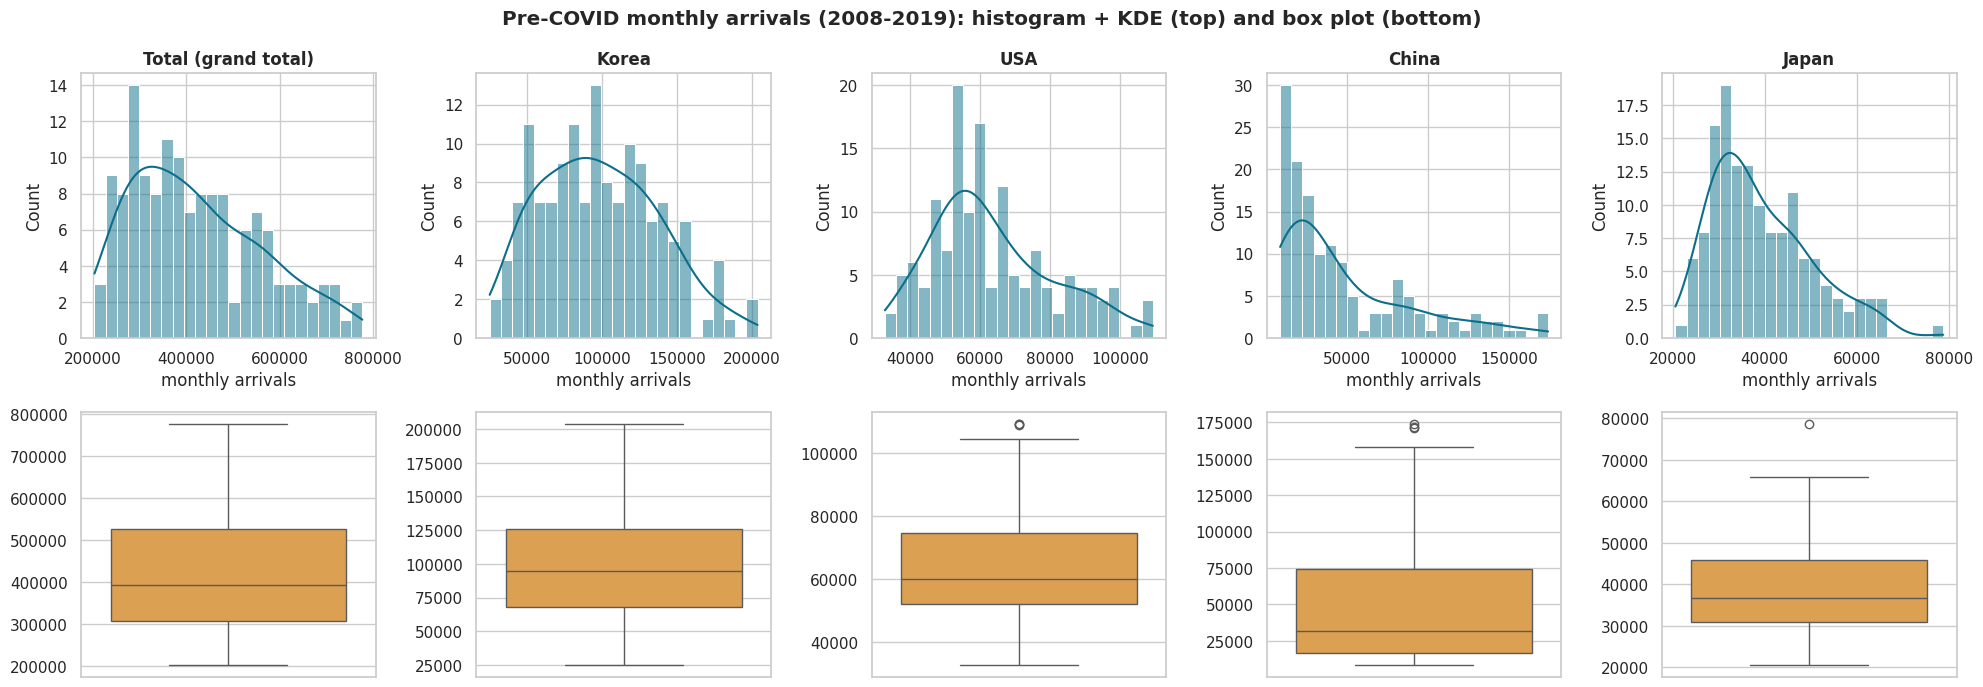

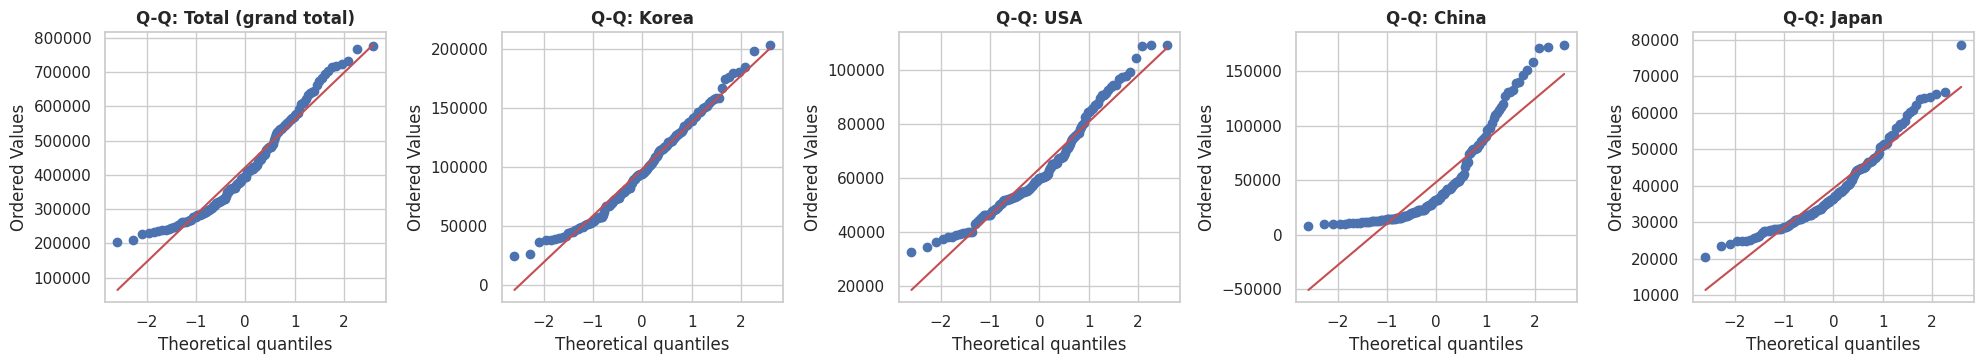

In [ ]:
fig,axes=plt.subplots(2,5,figsize=(20,7))
titles={'total':'Total (grand total)','KOREA':'Korea','USA':'USA','CHINA':'China','JAPAN':'Japan'}
for i,c in enumerate(focus):
    sns.histplot(pre[c],bins=24,kde=True,color=PAL['teal'],ax=axes[0,i]); axes[0,i].set_title(titles[c],fontweight='bold'); axes[0,i].set_xlabel('monthly arrivals')
    sns.boxplot(y=pre[c],color=PAL['orange'],ax=axes[1,i]); axes[1,i].set_ylabel('')
fig.suptitle('Pre-COVID monthly arrivals (2008-2019): histogram + KDE (top) and box plot (bottom)',fontweight='bold'); plt.tight_layout(); plt.show()
fig,axes=plt.subplots(1,5,figsize=(20,3.8))
for i,c in enumerate(focus):
    stats.probplot(pre[c],dist='norm',plot=axes[i]); axes[i].set_title('Q-Q: '+titles[c],fontweight='bold')
plt.tight_layout(); plt.show()

**Reading the plots.** Total and Korea look flat or mildly right-skewed; USA and Japan are right-skewed with a long upper tail; China piles up at low values with a long right tail, and its Q–Q plot bends away from the line at both ends. The box plots show a few high points for USA, China and Japan, tested formally below.

In [ ]:
rows=[];outl={}
for c in focus:
    s=pre[c]; q1,q3=s.quantile([.25,.75]); iqr=q3-q1
    o=s[(s<q1-1.5*iqr)|(s>q3+1.5*iqr)]; outl[c]=[f'{d:%b %Y}' for d in o.index]
    w,p=stats.shapiro(s); lw,lp=stats.shapiro(np.log10(s))
    rows.append([titles[c],w,p,'no' if p<.05 else 'yes',len(o),s.skew(),np.log10(s).skew(),lp,'yes' if abs(np.log10(s).skew())<abs(s.skew()) else 'NO'])
nt=pd.DataFrame(rows,columns=['variable','Shapiro W','p-value','normal @5%?','IQR outliers','skew (raw)','skew (log10)','p (log10)','|skew| reduced by log?']).set_index('variable')
display(nt.style.format({'Shapiro W':'{:.4f}','p-value':'{:.4f}','skew (raw)':'{:.3f}','skew (log10)':'{:.3f}','p (log10)':'{:.4f}'}))
print('Months flagged by the IQR rule:')
for c,v in outl.items():
    if v: print(f'  {titles[c]}: {v}')

,Shapiro W,p-value,normal @5%?,IQR outliers,skew (raw),skew (log10),p (log10),|skew| reduced by log?
variable,,,,,,,,
Total (grand total),0.9497,0.0000,no,0,0.598,0.068,0.0221,yes
Korea,0.9787,0.0244,no,0,0.355,-0.507,0.0052,NO
USA,0.9520,0.0001,no,3,0.685,0.116,0.1348,yes
China,0.8244,0.0000,no,3,1.318,0.261,0.0001,yes
Japan,0.9365,0.0000,no,1,0.900,0.335,0.0418,yes


Months flagged by the IQR rule:
  USA: ['Jan 2018', 'Jan 2019', 'Dec 2019']
  China: ['Feb 2019', 'Jul 2019', 'Aug 2019']
  Japan: ['Aug 2019']


**Interpretation.**
- Shapiro–Wilk rejects normality for all 5 variables (p < 0.05; Korea is the closest, p = 0.02). The series trend upward and carry seasonality, so they are not bell-shaped.
- The IQR rule flags 7 months: USA in Jan 2018, Jan 2019 and Dec 2019; China in Feb, Jul and Aug 2019; Japan in Aug 2019. All sit at the top of the growth trend (2018–2019), so they are genuine peaks, not errors, and none are removed.
- A log transform reduces |skewness| for 4 of 5 variables (Total, USA, China, Japan) but **not for Korea** (about 0.35 becomes −0.51). After the log only USA passes Shapiro–Wilk (p = 0.14), so the log is used in Section 6 to straighten and stabilise the relationship, not because it makes the data normal.
- These pre-COVID results are identical to those from an earlier compiled CSV of the same DOT data, which is an independent confirmation that the PDF extraction is right.

## 5. Univariate analysis II – growth, composition and seasonality
### 5.1 Annual arrivals, CAGR and recovery
2022 contains February–December only. The 2023 report stops in October, so market-level comparisons with 2019 use the **same ten months (January–October)**; full-year comparisons use the DOT grand totals, which are available for 2019, 2023 and 2024.

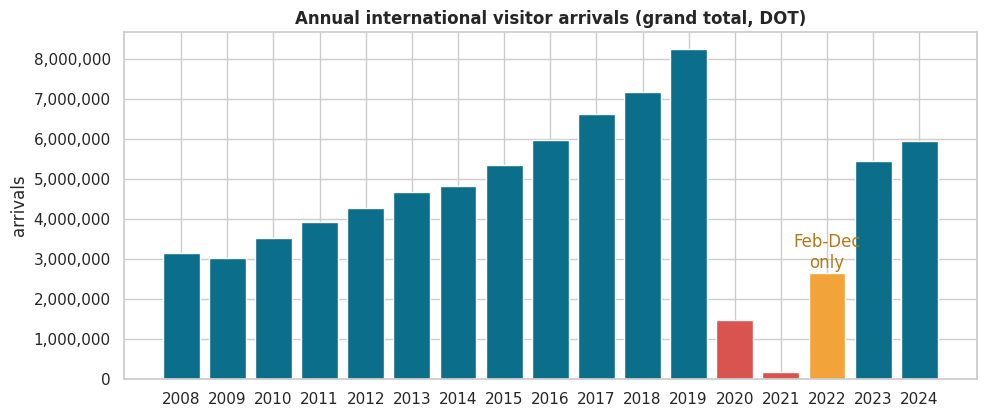

CAGR 2008-2019: 9.2% | 2009 vs 2008: -3.9% | 2020 vs 2019: -82.1% | 2021 vs 2020: -88.9%
Full-year totals: 2019 8,260,913 | 2023 5,450,557 (66% of 2019) | 2024 5,949,350 (72% of 2019, +9.2% vs 2023)
Jan-Oct totals: 2019 6,800,052 | 2023 4,445,280 (65%) | 2024 4,879,022 (72%) | 2024 vs 2023 +9.8%


,2008,2019,CAGR 2008-19 (%),Jan-Oct 2019,Jan-Oct 2023,2023 as % of 2019,2024 as % of 2019 (see 3.4)
market,,,,,,,
KOREA,"611,629","1,989,322",11.3,"1,609,172","1,170,498",72.7,82.1
USA,"578,246","1,064,440",5.7,"872,335","742,295",85.1,99.4
CHINA,"163,689","1,743,309",24.0,"1,499,524","223,411",14.9,18.8
JAPAN,"359,306","682,788",6.0,"569,625","247,674",43.5,64.4


In [ ]:
yr=wide[wide.reported].groupby('year').total.sum().reindex(range(2008,2025))
yr[2023]=FY23          # Jan-Oct from the 2023 PDF + Nov-Dec implied by the full-year figure in the 2024 PDF
fig,ax=plt.subplots(figsize=(11,4.5))
cols=[PAL['teal'] if y<=2019 or y in (2023,2024) else (PAL['red'] if y in (2020,2021) else PAL['orange']) for y in yr.index]
ax.bar(yr.index.astype(str),yr,color=cols)
ax.text(list(yr.index).index(2022),yr[2022]+120000,'Feb-Dec\nonly',ha='center',color='#B07A1B')
ax.set_title('Annual international visitor arrivals (grand total, DOT)',fontweight='bold'); ax.set_ylabel('arrivals'); ax.yaxis.set_major_formatter(lambda v,_:f'{v:,.0f}'); plt.show()
print(f"CAGR 2008-2019: {cagr(yr[2008],yr[2019],11):.1%} | 2009 vs 2008: {yr[2009]/yr[2008]-1:+.1%} | 2020 vs 2019: {yr[2020]/yr[2019]-1:+.1%} | 2021 vs 2020: {yr[2021]/yr[2020]-1:+.1%}")
print(f"Full-year totals: 2019 {yr[2019]:,.0f} | 2023 {yr[2023]:,.0f} ({yr[2023]/yr[2019]:.0%} of 2019) | 2024 {yr[2024]:,.0f} ({yr[2024]/yr[2019]:.0%} of 2019, {yr[2024]/yr[2023]-1:+.1%} vs 2023)")
jo=lambda y: wide[(wide.year==y)&(wide.month<=10)]          # common window: Jan-Oct (2023 data stop in October)
t19,t23,t24=[jo(y).total.sum() for y in (2019,2023,2024)]
print(f'Jan-Oct totals: 2019 {t19:,.0f} | 2023 {t23:,.0f} ({t23/t19:.0%}) | 2024 {t24:,.0f} ({t24/t19:.0%}) | 2024 vs 2023 {t24/t23-1:+.1%}')
rows=[]
for c in ['KOREA','USA','CHINA','JAPAN']:
    y08=wide[wide.year==2008][c].sum(); y19=wide[wide.year==2019][c].sum()
    rows.append([c,y08,y19,100*cagr(y08,y19,11),jo(2019)[c].sum(),jo(2023)[c].sum(),100*jo(2023)[c].sum()/jo(2019)[c].sum(),100*jo(2024)[c].sum()/jo(2019)[c].sum()])
cg=pd.DataFrame(rows,columns=['market','2008','2019','CAGR 2008-19 (%)','Jan-Oct 2019','Jan-Oct 2023','2023 as % of 2019','2024 as % of 2019 (see 3.4)']).set_index('market')
display(cg.style.format({'2008':'{:,.0f}','2019':'{:,.0f}','Jan-Oct 2019':'{:,.0f}','Jan-Oct 2023':'{:,.0f}','CAGR 2008-19 (%)':'{:.1f}','2023 as % of 2019':'{:.1f}','2024 as % of 2019 (see 3.4)':'{:.1f}'}))

**Growth.** Arrivals grew from 3,139,422 (2008) to 8,260,913 (2019), a CAGR of **9.2%** a year. The only pre-COVID dip was 2009 (−3.9%, global financial crisis). 2020 fell 82.1% to 1,482,535 and 2021 fell a further 88.9% to 163,879.

**Recovery.** 2022 (February–December) reached 2,653,858. Full-year 2023 was 5,450,557, **66% of 2019**, and 2024 was 5,949,350, **72% of 2019** (+9.2% vs 2023). On the common January–October window the figures are 65% (2023) and 72% (2024). Full recovery had not happened by the end of 2024.

**By market.** China had the fastest pre-COVID growth (24.0% a year) but has recovered least: Jan–Oct 2023 was only 14.9% of 2019 (18.8% in 2024). Among the four largest markets the USA recovered most (85.1% in 2023), then Korea (72.7%) and Japan (43.5%). The 2024 column (USA 99.4%, Korea 82.1%, Japan 64.4%) follows the broader 2024 basis described in Section 3.4, so we read it as direction, not as an exact level.

In [ ]:
g19,g23=jo(2019)[core].sum(),jo(2023)[core].sum()
gap=(g19-g23).sort_values(ascending=False)
gt=pd.DataFrame({'Jan-Oct 2019':g19,'Jan-Oct 2023':g23,'gap (arrivals)':g19-g23,'share of core gap (%)':100*(g19-g23)/(g19-g23).sum()}).loc[gap.index].head(8)
print(f'Gap between Jan-Oct 2019 and Jan-Oct 2023, 50 core markets (same measurement basis): {gap.sum():,.0f}  | all arrivals incl. overseas Filipinos: {t19-t23:,.0f}')
display(gt.style.format({'Jan-Oct 2019':'{:,.0f}','Jan-Oct 2023':'{:,.0f}','gap (arrivals)':'{:,.0f}','share of core gap (%)':'{:.1f}'}))

Gap between Jan-Oct 2019 and Jan-Oct 2023, 50 core markets (same measurement basis): 2,655,646  | all arrivals incl. overseas Filipinos: 2,354,772


,Jan-Oct 2019,Jan-Oct 2023,gap (arrivals),share of core gap (%)
CHINA,"1,499,524","223,411","1,276,113",48.1
KOREA,"1,609,172","1,170,498","438,674",16.5
JAPAN,"569,625","247,674","321,951",12.1
USA,"872,335","742,295","130,040",4.9
TAIWAN,"282,220","166,628","115,592",4.4
INDIA,"112,247","58,504","53,743",2.0
UNITED KINGDOM,"168,954","125,009","43,945",1.7
MALAYSIA,"115,619","79,609","36,010",1.4


**Where the remaining gap sits.** Jan–Oct 2023 is 2,655,646 arrivals below Jan–Oct 2019 across the 50 core markets (same basis in both years). **China accounts for 48.1% of that gap**, Korea 16.5%, Japan 12.1%, USA 4.9% and Taiwan 4.4%. The gap is therefore mostly a China story, followed by Korea and Japan. For all arrivals, including overseas Filipinos, the gap is smaller (2,354,772) because overseas-Filipino arrivals grew.

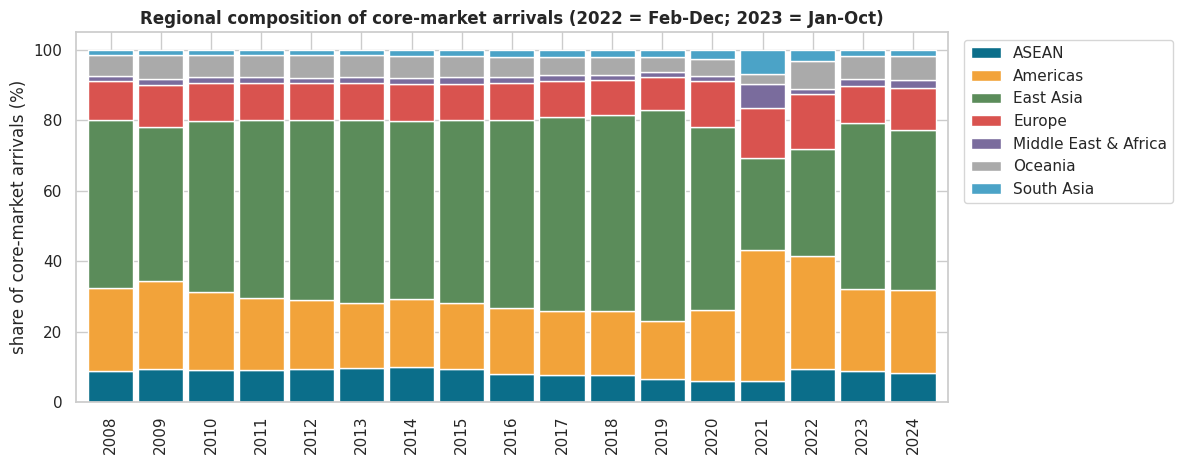

region,ASEAN,Americas,East Asia,Europe,Middle East & Africa,Oceania,South Asia
year,,,,,,,
2008,8.80,23.70,47.60,10.90,1.50,6.10,1.40
2019,6.50,16.40,60.10,9.40,1.20,4.40,2.00
2021,6.10,37.10,26.10,14.20,6.90,2.80,6.80
2022,9.50,32.00,30.40,15.40,1.50,8.10,3.00
2023,8.80,23.40,47.20,10.60,1.80,6.60,1.80
2024,8.30,23.40,45.70,11.80,2.40,6.80,1.70


Total arrivals in 2021 (grand total): 163,879


In [ ]:
comp=long[long.reported].groupby(['year','region']).arrivals.sum().unstack()
order=['ASEAN','Americas','East Asia','Europe','Middle East & Africa','Oceania','South Asia']
share=100*comp.div(comp.sum(axis=1),axis=0)[order]
fig,ax=plt.subplots(figsize=(12,4.8))
share.plot(kind='bar',stacked=True,ax=ax,width=.9,color=[PAL['teal'],PAL['orange'],PAL['green'],PAL['red'],PAL['purple'],'#AAAAAA','#4BA3C7'])
ax.set_title('Regional composition of core-market arrivals (2022 = Feb-Dec; 2023 = Jan-Oct)',fontweight='bold'); ax.set_ylabel('share of core-market arrivals (%)'); ax.set_xlabel('')
ax.legend(bbox_to_anchor=(1.01,1),loc='upper left'); plt.tight_layout(); plt.show()
display(share.loc[[2008,2019,2021,2022,2023,2024]].round(1))
print(f"Total arrivals in 2021 (grand total): {wide.loc['2021','total'].sum():,.0f}")

**Interpretation.** East Asia's share rose from 47.6% (2008) to 60.1% (2019) while the Americas fell from 23.7% to 16.4%. In 2023 East Asia fell back to 47.2% as China lagged and the Americas rebounded to 23.4%; in 2024 East Asia was 45.7%. *Caution:* the 2021 bar (Americas 37%) is an artefact of a tiny total (163,879 arrivals), the 2022 bar is February–December on the nationality basis, and 2023 covers ten months.

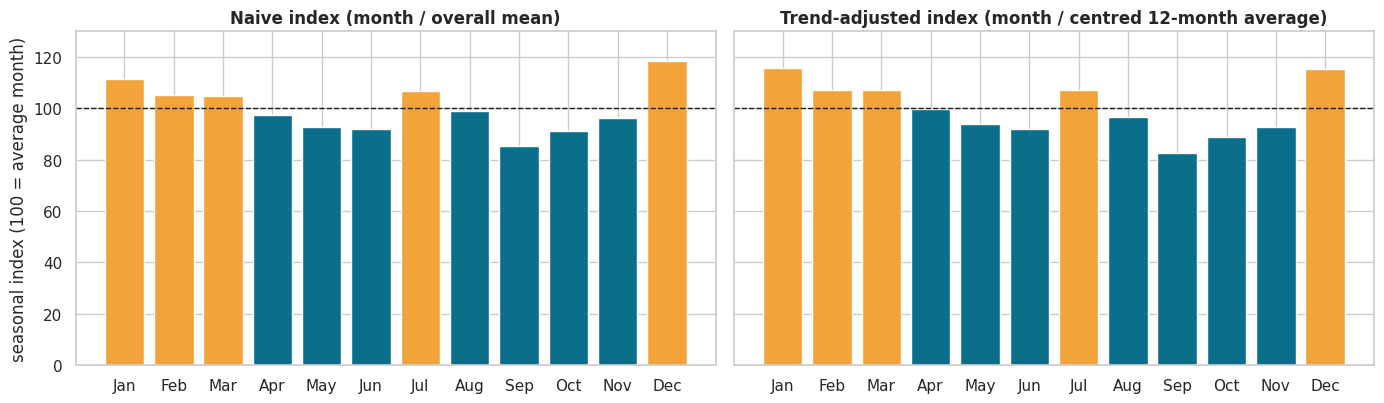

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
naive,111.50,105.20,104.60,97.50,92.70,91.70,106.70,98.80,85.20,91.30,96.30,118.40
trend-adjusted,115.80,107.00,107.00,99.50,93.80,92.10,107.00,96.80,82.50,88.70,92.70,115.50


In [ ]:
mn=['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
tot=wide.total.loc['2008-01-01':'2019-12-01']
naive=(tot/tot.mean()*100).groupby(tot.index.month).mean()
cma=tot.rolling(12,center=True).mean().rolling(2).mean().shift(-1)   # centred 2x12 moving average = the trend
ratio=(tot/cma*100).dropna()                                          # first and last 6 months have no trend value
adj=ratio.groupby(ratio.index.month).mean()
fig,axes=plt.subplots(1,2,figsize=(14,4.2),sharey=True)
for ax,s_,t in zip(axes,[naive,adj],['Naive index (month / overall mean)','Trend-adjusted index (month / centred 12-month average)']):
    ax.bar(mn,s_.values,color=[PAL['orange'] if v>100 else PAL['teal'] for v in s_.values]); ax.axhline(100,color='k',ls='--',lw=1); ax.set_title(t,fontweight='bold'); ax.set_ylim(0,130)
axes[0].set_ylabel('seasonal index (100 = average month)'); plt.tight_layout(); plt.show()
display(pd.DataFrame({'naive':naive.values,'trend-adjusted':adj.values},index=mn).T.round(1))

**Interpretation.** Because arrivals trend upward, later months of a year look larger just from growth, so the naive index overstates December. The right-hand panel divides each month by a centred 12-month average (the trend) instead. After this correction **January is the peak (115.8) with December (115.5) almost level**, then February, March and July (107.0); the quietest months are September (82.5) and October (88.7). Naively December looked clearly highest (118.4), which was partly trend. Peaks around the year-end holidays and winter fit holiday and winter travel; the weak Sep–Nov period coincides with the rainy and typhoon season, though this data cannot show the cause. Promotions should follow this cycle.

## 6. Bivariate analysis – numerical vs numerical
The instruction sheet limits bivariate analysis to **two numerical variables**. Our pairs are monthly arrivals from two markets (mainly Korea vs China), a market vs the total, and the same pair across periods. Because every series trends upward, we deliberately test whether relationships survive once the trend is removed.

### 6.1 Correlation matrices: levels vs year-over-year growth

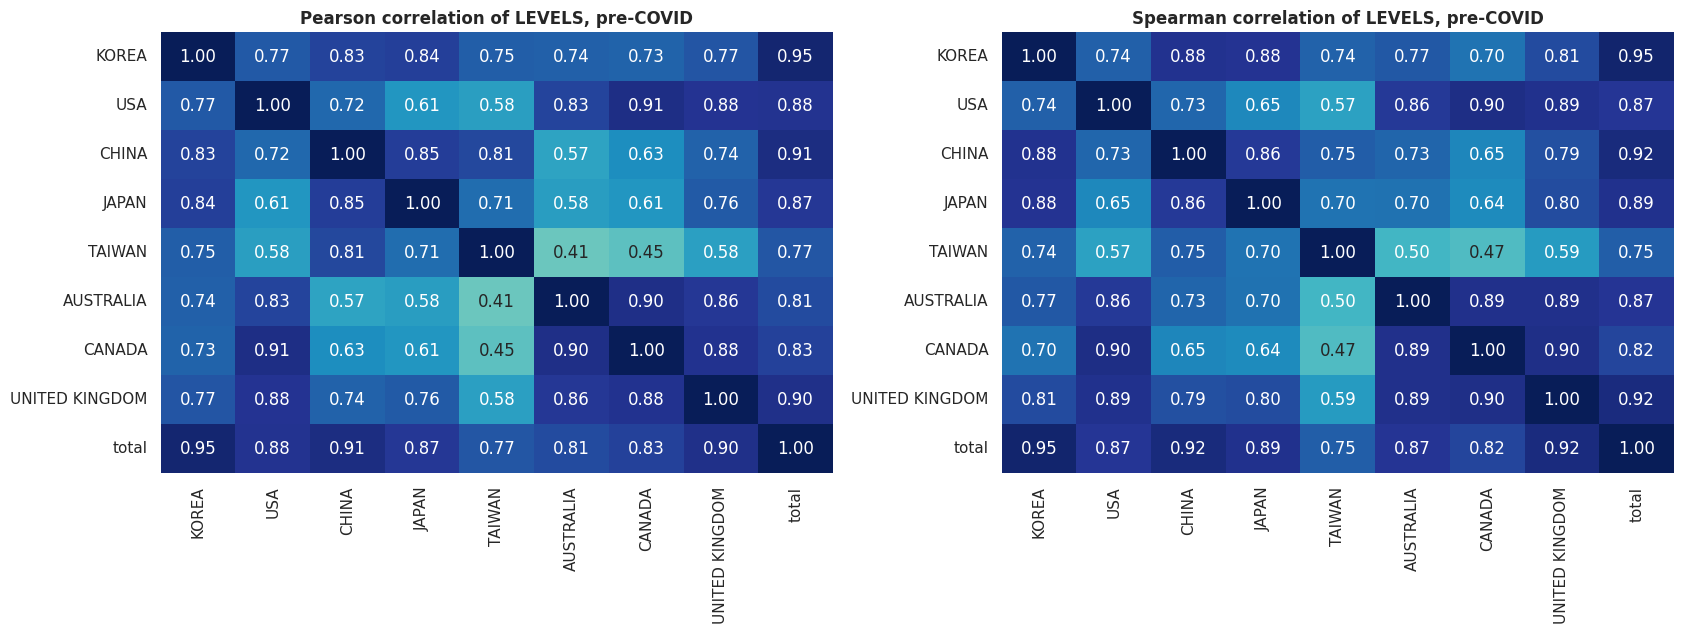

In [ ]:
mk8=['KOREA','USA','CHINA','JAPAN','TAIWAN','AUSTRALIA','CANADA','UNITED KINGDOM']
lv=pre[mk8+['total']]
fig,axes=plt.subplots(1,2,figsize=(17,6.5))
for ax,m,t in zip(axes,['pearson','spearman'],['Pearson correlation of LEVELS, pre-COVID','Spearman correlation of LEVELS, pre-COVID']):
    sns.heatmap(lv.corr(method=m),annot=True,fmt='.2f',cmap='YlGnBu',vmin=0,vmax=1,cbar=False,ax=ax); ax.set_title(t,fontweight='bold')
plt.tight_layout(); plt.show()

YoY observations used: 132


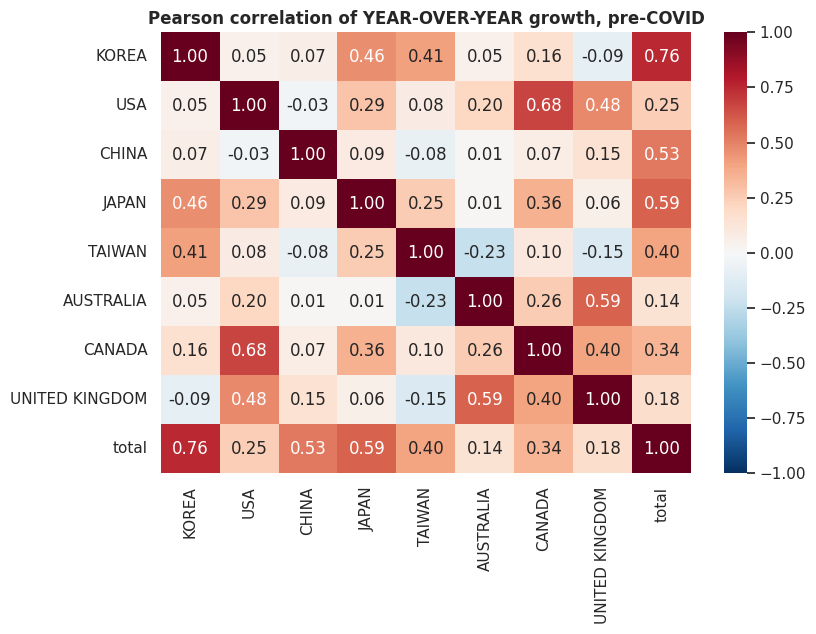

Level correlations (off-diagonal, 8 markets): min 0.41 (TAIWAN vs AUSTRALIA), max 0.91 (USA vs CANADA), median 0.75
YoY-growth correlations (off-diagonal, 8 markets): median 0.10


In [ ]:
# Year-over-year log growth removes both the shared upward trend and most of the seasonality
yoy=np.log(wide[mk8+['total']]).diff(12)
yoy_pre=yoy.loc['2009-01-01':'2019-12-01']
print('YoY observations used:',yoy_pre.dropna().shape[0])
fig,ax=plt.subplots(figsize=(8.5,6.5))
sns.heatmap(yoy_pre.corr(),annot=True,fmt='.2f',cmap='RdBu_r',vmin=-1,vmax=1,ax=ax); ax.set_title('Pearson correlation of YEAR-OVER-YEAR growth, pre-COVID',fontweight='bold'); plt.tight_layout(); plt.show()
lc=lv[mk8].corr().where(~np.eye(8,dtype=bool)).stack()
print(f'Level correlations (off-diagonal, 8 markets): min {lc.min():.2f} ({" vs ".join(lc.idxmin())}), max {lc.max():.2f} ({" vs ".join(lc.idxmax())}), median {lc.median():.2f}')
print(f'YoY-growth correlations (off-diagonal, 8 markets): median {yoy_pre[mk8].corr().where(~np.eye(8,dtype=bool)).stack().median():.2f}')

**Interpretation.**
- In levels, every pair of the eight markets is positively correlated (lowest 0.41, Taiwan vs Australia; highest 0.91, USA vs Canada), with a median off-diagonal r of 0.75. Spearman gives the same picture. Spearman guards against extreme values but **not** against a shared trend or shared seasonality, so it does not settle the question.
- Year-over-year log growth removes most of the trend and seasonality. On that basis the median off-diagonal correlation falls to **0.10**. Most of the strong level correlations therefore reflect markets growing in the same decade, not markets moving together month to month.
- The high USA–Canada value is also plausible as shared holiday travel by the Filipino diaspora and others around the same dates.

### 6.2 Korea vs China: correlation and regression

,Value
n (pre-COVID months),144
Pearson r,"0.829 (95% CI 0.77 to 0.87), p = 1.1e-37"
Spearman rho,"0.884, p = 1.3e-48"
Linear regression,"China = -37,609 + 0.872 x Korea"
R-squared,0.688


Log-log: elasticity 1.60, R2 0.725; naive 95% CI 1.44 to 1.76; autocorrelation-robust (Newey-West) 95% CI 1.23 to 1.97


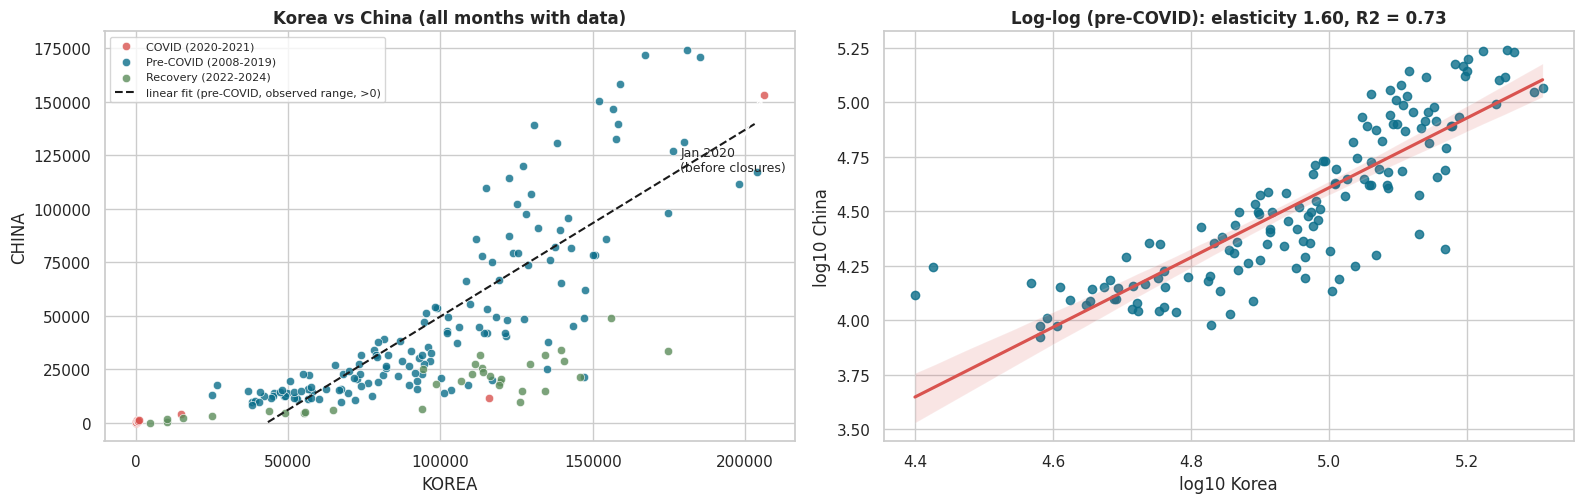

In [ ]:
d=pre[['KOREA','CHINA']].copy()
r_pool,p_pool=stats.pearsonr(d.KOREA,d.CHINA); rs,ps=stats.spearmanr(d.KOREA,d.CHINA); lo,hi=corr_ci(r_pool,len(d))
lr=stats.linregress(d.KOREA,d.CHINA)
res=pd.DataFrame({'Value':[len(d),f'{r_pool:.3f} (95% CI {lo:.2f} to {hi:.2f}), p = {p_pool:.1e}',f'{rs:.3f}, p = {ps:.1e}',f'China = {lr.intercept:,.0f} + {lr.slope:.3f} x Korea',f'{lr.rvalue**2:.3f}']},
    index=['n (pre-COVID months)','Pearson r','Spearman rho','Linear regression','R-squared']); display(res)
X=sm.add_constant(np.log10(d.KOREA)); y=np.log10(d.CHINA)
ols=sm.OLS(y,X).fit(); hac=sm.OLS(y,X).fit(cov_type='HAC',cov_kwds={'maxlags':12})
el=ols.params.iloc[1]; lo_h,hi_h=hac.conf_int().iloc[1]
print(f'Log-log: elasticity {el:.2f}, R2 {ols.rsquared:.3f}; naive 95% CI {ols.conf_int().iloc[1,0]:.2f} to {ols.conf_int().iloc[1,1]:.2f}; autocorrelation-robust (Newey-West) 95% CI {lo_h:.2f} to {hi_h:.2f}')
fig,axes=plt.subplots(1,2,figsize=(16,5.2))
a=wide[wide.reported]; colmap={'Pre-COVID (2008-2019)':PAL['teal'],'COVID (2020-2021)':PAL['red'],'Recovery (2022-2024)':PAL['green']}
for per,g in a.groupby('period'): axes[0].scatter(g.KOREA,g.CHINA,s=36,alpha=.8,color=colmap[per],label=per,edgecolor='white',lw=.5)
xs=np.linspace(d.KOREA.min(),d.KOREA.max(),50); ys=lr.intercept+lr.slope*xs; keep=ys>0
axes[0].plot(xs[keep],ys[keep],'k--',label='linear fit (pre-COVID, observed range, >0)')
j=a.loc['2020-01-01']; axes[0].annotate('Jan 2020\n(before closures)',(j.KOREA,j.CHINA),xytext=(-60,-55),textcoords='offset points',arrowprops=dict(arrowstyle='->'),fontsize=9)
axes[0].set_xlabel('KOREA'); axes[0].set_ylabel('CHINA'); axes[0].set_title('Korea vs China (all months with data)',fontweight='bold'); axes[0].legend(fontsize=8)
sns.regplot(x=np.log10(d.KOREA),y=np.log10(d.CHINA),ax=axes[1],scatter_kws={'color':PAL['teal'],'s':36,'alpha':.8},line_kws={'color':PAL['red']})
axes[1].set_xlabel('log10 Korea'); axes[1].set_ylabel('log10 China'); axes[1].set_title(f'Log-log (pre-COVID): elasticity {el:.2f}, R2 = {ols.rsquared:.2f}',fontweight='bold'); plt.tight_layout(); plt.show()

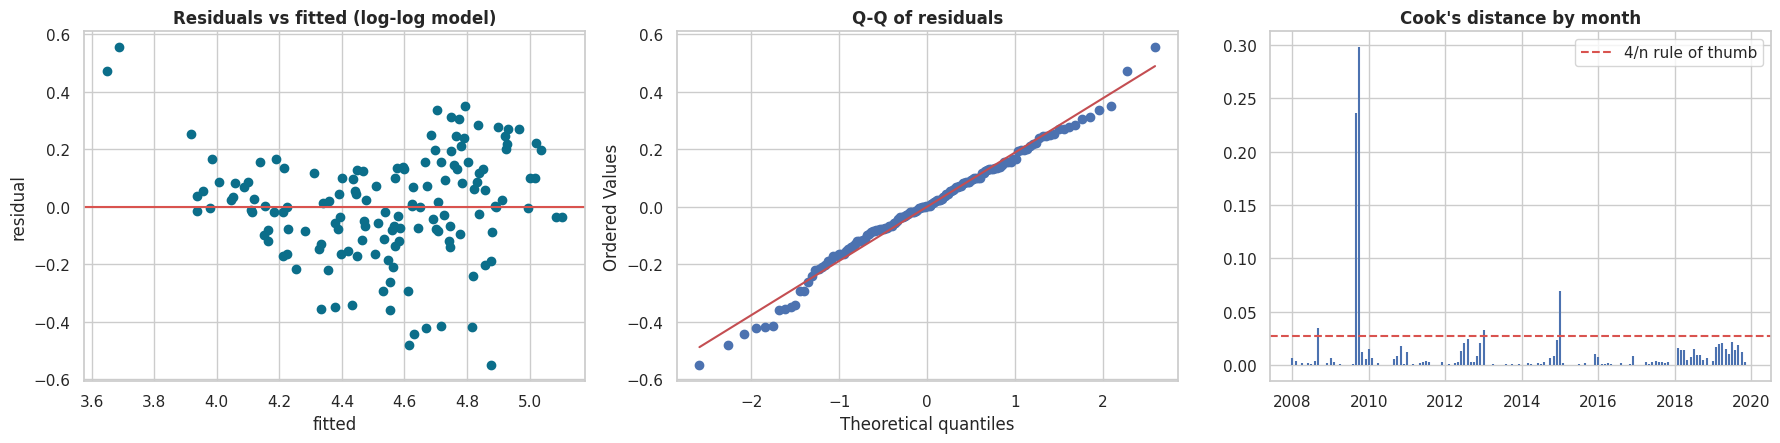

Residual Shapiro-Wilk W = 0.986 (p = 0.171) | Durbin-Watson = 0.62 (2 = no autocorrelation)
Most influential months: ['Oct 2009', 'Sep 2009', 'Jan 2015'] [0.298 0.236 0.069] | 4/n threshold = 0.028
Refit without 5 months above the 4/n rule: elasticity 1.79, R2 0.787
Correlation of log Korea and log China after removing each series' linear time trend: 0.14 (before: 0.85)
Jan 2020: Korea 206,062, China 153,109


In [ ]:
resid=ols.resid; infl=ols.get_influence(); cook=infl.cooks_distance[0]
fig,axes=plt.subplots(1,3,figsize=(18,4.6))
axes[0].scatter(ols.fittedvalues,resid,color=PAL['teal']); axes[0].axhline(0,color=PAL['red']); axes[0].set_title('Residuals vs fitted (log-log model)',fontweight='bold'); axes[0].set_xlabel('fitted'); axes[0].set_ylabel('residual')
stats.probplot(resid,dist='norm',plot=axes[1]); axes[1].set_title('Q-Q of residuals',fontweight='bold')
axes[2].stem(d.index,cook,markerfmt=' ',basefmt=' '); axes[2].axhline(4/len(d),color=PAL['red'],ls='--',label='4/n rule of thumb'); axes[2].set_title("Cook's distance by month",fontweight='bold'); axes[2].legend(); plt.tight_layout(); plt.show()
sw=stats.shapiro(resid)
print(f'Residual Shapiro-Wilk W = {sw[0]:.3f} (p = {sw[1]:.3f}) | Durbin-Watson = {durbin_watson(resid):.2f} (2 = no autocorrelation)')
top=pd.Series(cook,index=d.index).sort_values(ascending=False).head(3)
print('Most influential months:',[f'{i:%b %Y}' for i in top.index],np.round(top.values,3),'| 4/n threshold =',round(4/len(d),3))
mask=pd.Series(cook,index=d.index)<4/len(d)
ols2=sm.OLS(y[mask.values],X[mask.values]).fit()
print(f'Refit without {int((~mask).sum())} months above the 4/n rule: elasticity {ols2.params.iloc[1]:.2f}, R2 {ols2.rsquared:.3f}')
t=np.arange(len(d)); detr=lambda s: s-np.polyval(np.polyfit(t,s,1),t)
r_dt=stats.pearsonr(detr(np.log10(d.KOREA).values),detr(np.log10(d.CHINA).values))[0]
print(f'Correlation of log Korea and log China after removing each series\' linear time trend: {r_dt:.2f} (before: {stats.pearsonr(np.log10(d.KOREA),np.log10(d.CHINA))[0]:.2f})')
print(f"Jan 2020: Korea {wide.loc['2020-01-01','KOREA']:,.0f}, China {wide.loc['2020-01-01','CHINA']:,.0f}")

**Interpretation.**
- *Linear model.* Before COVID, Korean arrivals alone explain 69% of the variation in Chinese arrivals (r = 0.829, 95% CI 0.77 to 0.87). The straight line predicts negative arrivals below about 43,000 Korean arrivals, which is impossible, so the log–log model is the better description.
- *Log–log model.* A 1% rise in Korean arrivals goes with about a 1.6% rise in Chinese arrivals (R² = 0.73). Consecutive months are strongly related (Durbin–Watson = 0.62, far below 2), so the ordinary confidence interval (1.44 to 1.76) is too narrow; the autocorrelation-robust Newey–West interval is **1.23 to 1.97**. The elasticity above 1 is consistent with China growing faster than Korea (24.0% vs 11.3% a year).
- *Model checks.* Residuals are roughly normal (Shapiro p = 0.171) but the residual-vs-fitted plot is curved, so the elasticity is not constant. Sep and Oct 2009 are the most influential months (Cook's distance 0.24 and 0.30, against a 4/n threshold of 0.028). Removing the 5 months above the threshold moves the elasticity from 1.60 to 1.79, so the exact value is sensitive; treat it as "between about 1.2 and 2".
- *Trend.* After removing each series' linear time trend, the Korea–China correlation drops from **0.85 to 0.14**. Most of the 0.83 is therefore a shared upward trend, not month-to-month co-movement.
- *Pandemic and recovery points.* Most COVID months (red) sit in the bottom-left, but January 2020 sits at the top right (Korea 206,062; China 153,109) because it was before border closures. The recovery months (green) lie well below the pre-COVID cloud: Korean arrivals returned much faster than Chinese arrivals.

### 6.3 The same pairs in three periods

In [ ]:
pairs=[('CHINA','JAPAN'),('KOREA','CHINA'),('KOREA','total'),('KOREA','USA'),('USA','JAPAN')]
pers=['Pre-COVID (2008-2019)','COVID (2020-2021)','Recovery (2022-2024)']
rows=[]
for a_,b_ in pairs:
    for per in pers:
        g=wide[(wide.period==per)&wide.reported]; rr_,pp_=stats.pearsonr(g[a_],g[b_]); lo,hi=corr_ci(rr_,len(g)); rho=stats.spearmanr(g[a_],g[b_])[0]
        rows.append([f'{a_.title()} vs {b_.title()}',per.split(' ')[0],len(g),rr_,f'{lo:.2f} to {hi:.2f}',pp_,rho])
ct=pd.DataFrame(rows,columns=['pair','period','n','Pearson r','95% CI','p-value','Spearman rho'])
display(ct.pivot(index='pair',columns='period',values='Pearson r')[['Pre-COVID','COVID','Recovery']].round(2))
display(ct[ct.period=='Recovery'].set_index('pair').drop(columns='period').style.format({'Pearson r':'{:.2f}','p-value':'{:.3f}','Spearman rho':'{:.2f}'}))
# sensitivity: recovery without 2024 (2024 market rows follow a slightly different basis, see 3.4)
g=wide[(wide.period=='Recovery (2022-2024)')&wide.reported&(wide.year<=2023)]
print(f'Sensitivity - Recovery 2022-2023 only (n = {len(g)}):',{f'{a_.title()} vs {b_.title()}':round(stats.pearsonr(g[a_],g[b_])[0],2) for a_,b_ in pairs})

period,Pre-COVID,COVID,Recovery
pair,,,
China vs Japan,0.85,0.66,0.79
Korea vs China,0.83,0.90,0.84
Korea vs Total,0.95,1.00,0.95
Korea vs Usa,0.77,0.99,0.80
Usa vs Japan,0.61,0.95,0.66


,n,Pearson r,95% CI,p-value,Spearman rho
pair,,,,,
China vs Japan,33,0.79,0.61 to 0.89,0.000,0.78
Korea vs China,33,0.84,0.70 to 0.92,0.000,0.79
Korea vs Total,33,0.95,0.90 to 0.97,0.000,0.88
Korea vs Usa,33,0.80,0.64 to 0.90,0.000,0.73
Usa vs Japan,33,0.66,0.41 to 0.82,0.000,0.64


Sensitivity - Recovery 2022-2023 only (n = 21): {'China vs Japan': np.float64(0.93), 'Korea vs China': np.float64(0.85), 'Korea vs Total': np.float64(0.94), 'Korea vs Usa': np.float64(0.79), 'Usa vs Japan': np.float64(0.58)}


**Interpretation.**
- Before COVID all pairs move together (r from 0.61 to 0.95), largely through the shared growth trend.
- During COVID almost every pair jumps toward r ≈ 1 (Korea vs USA 0.99). The data form two clusters (before and after the collapse), so this reflects one common shock, not a special link; these values are not meaningful relationships.
- In the recovery (n = 33 months, Feb 2022 to Dec 2024) all pairs are clearly positive (p < 0.001): Korea–China 0.84 (95% CI 0.70 to 0.92), Korea–USA 0.80, China–Japan 0.79, USA–Japan 0.66 (CI 0.41 to 0.82). With the first 21 months only (2022–2023) the values are similar (0.58 to 0.94). These are **not** evidence of tighter links: every market was climbing out of the border closures at the same time, so the series share a strong reopening trend, exactly the problem found in Section 6.2. Korea vs Total stays high (0.95) because Korea is now about a quarter of arrivals.
- Part of the recovery window uses the 2022 nationality basis and the broader 2024 basis (Section 3.4), which is another reason to read these values as descriptive.

### 6.4 Rolling correlation

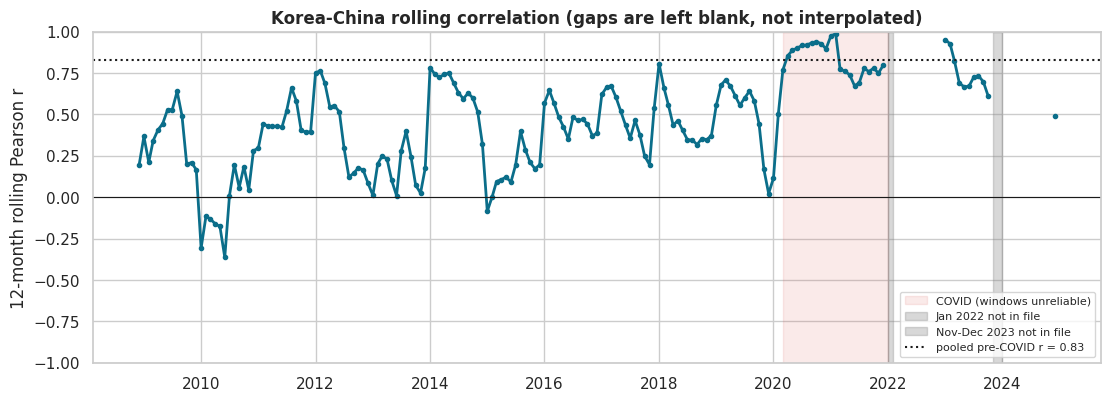

Pre-COVID rolling r: min -0.36, median 0.40, max 0.81 | share of windows below the pooled r: 100%
Recovery windows with 12 consecutive months: 11 (ending Jan 2023, Feb 2023, Mar 2023, Apr 2023, May 2023, Jun 2023, Jul 2023, Aug 2023, Sep 2023, Oct 2023, Dec 2024) -> r = 0.95, 0.93, 0.82, 0.69, 0.67, 0.67, 0.72, 0.73, 0.70, 0.61, 0.49


In [ ]:
calendar=wide[['KOREA','CHINA']]                                   # keeps Jan 2022 and Nov-Dec 2023 as NaN rows
roll=calendar.KOREA.rolling(12,min_periods=12).corr(calendar.CHINA)   # any window touching a gap stays NaN
fig,ax=plt.subplots(figsize=(13,4.3))
ax.plot(roll.index,roll,color=PAL['teal'],lw=2,marker='.')
ax.axvspan(pd.Timestamp('2020-03-01'),pd.Timestamp('2021-12-31'),color=PAL['red'],alpha=.12,label='COVID (windows unreliable)')
for s_,e_,l_ in [('2022-01-01','2022-01-31','Jan 2022 not in file'),('2023-11-01','2023-12-31','Nov-Dec 2023 not in file')]:
    ax.axvspan(pd.Timestamp(s_),pd.Timestamp(e_),color='grey',alpha=.3,label=l_)
ax.axhline(r_pool,color='k',ls=':',label=f'pooled pre-COVID r = {r_pool:.2f}'); ax.axhline(0,color='k',lw=.8)
ax.set_ylim(-1,1); ax.set_ylabel('12-month rolling Pearson r'); ax.set_title('Korea-China rolling correlation (gaps are left blank, not interpolated)',fontweight='bold'); ax.legend(loc='lower right',fontsize=8); plt.show()
pr=roll['2008':'2019'].dropna(); rr=roll['2022':].dropna()
print(f'Pre-COVID rolling r: min {pr.min():.2f}, median {pr.median():.2f}, max {pr.max():.2f} | share of windows below the pooled r: {(pr<r_pool).mean():.0%}')
print(f'Recovery windows with 12 consecutive months: {len(rr)} (ending {", ".join(f"{d:%b %Y}" for d in rr.index)}) -> r = {", ".join(f"{v:.2f}" for v in rr.values)}')

**Interpretation.** Before COVID, the 12-month rolling correlation ranges from −0.36 to 0.81 (median 0.40) and **never reaches the pooled 0.83**. The Korea–China link is therefore weaker and less stable inside any given year than the pooled figure suggests, which matches the trend finding in 6.2. The values near 0.9 in 2020–21 are not a real tightening: each window contains the collapse and early recovery, which moves both series together. The three missing months are left blank instead of being joined by a line, so only 11 recovery windows have 12 consecutive months. The windows ending Jan–Feb 2023 show 0.95 and 0.93 (dominated by the 2022 reopening), and the correlation then **falls to 0.61 by October 2023** (with a small rebound in mid-2023); the window covering January–December 2024 gives **0.49**, close to the pre-COVID within-year median of 0.40. As the reopening trend fades, the Korea–China link looks much like it did before COVID, which is consistent with 6.1 and 6.2.

In [ ]:
shr=lambda y0,m1,c: wide[(wide.year==y0)&(wide.month<=m1)][c].sum()/wide[(wide.year==y0)&(wide.month<=m1)].total.sum()
for c,l in [('CHINA','China'),('KOREA','Korea'),('USA','USA')]:
    print(f'{l} share of all arrivals, Jan-Oct: 2019 {shr(2019,10,c):.1%} | 2023 {shr(2023,10,c):.1%} | 2024 {shr(2024,10,c):.1%}')
print('Lowest month:',f'{wide.total.idxmin():%b %Y}',int(wide.total.min()),'| March 2020:',int(wide.loc['2020-03-01','total']),'| Jan 2020:',int(wide.loc['2020-01-01','total']),'| fall Jan->Apr 2020:',f"{wide.loc['2020-04-01','total']/wide.loc['2020-01-01','total']-1:.1%}")

China share of all arrivals, Jan-Oct: 2019 22.1% | 2023 5.0% | 2024 5.8%
Korea share of all arrivals, Jan-Oct: 2019 23.7% | 2023 26.3% | 2024 27.1%
USA share of all arrivals, Jan-Oct: 2019 12.8% | 2023 16.7% | 2024 17.8%
Lowest month: Apr 2020 948 | March 2020: 139325 | Jan 2020: 796164 | fall Jan->Apr 2020: -99.9%


## 7. Conclusions, recommendations and limitations

This section pulls together what the analysis found, explains what the findings mean in practice, and sets out why we recommend the actions we do and how they could be carried out. It is written to be read on its own, without the earlier technical sections.

### 7.1 Summary of conclusions

**1. Philippine tourism grew strongly and steadily until 2019.**
Yearly arrivals rose from about 3.1 million in 2008 to about 8.3 million in 2019, an average growth of 9.2% a year. The only dip was in 2009 (−3.9%), during the global financial crisis.
*What this means:* for more than a decade, growth was the normal state of affairs and setbacks were short. This is the standard against which the current recovery should be judged.

**2. COVID-19 was a sudden break, not an ordinary bad year.**
Monthly arrivals fell from 796,164 in January 2020 to just 948 in April 2020. Yearly arrivals dropped 82.1% in 2020 and a further 88.9% in 2021.
*What this means:* the pandemic years behave so differently from the years before that past growth rates cannot simply be carried forward. Targets built only on the 2008–2019 trend would be too optimistic for the near term.

**3. The recovery is real, but it is unfinished and uneven.**
Arrivals reached 66% of the 2019 level in 2023 and 72% in 2024 (5,949,350 visitors, up 9.2% on 2023). Markets recovered at very different speeds. Comparing the same ten months of 2023 with 2019, the USA reached 85.1% of its earlier level, Korea 72.7%, Japan 43.5% and China only 14.9%.
*What this means:* a single national figure hides very different stories. A national target can look on track while some of the most important markets are still far behind.

**4. China accounts for almost half of the remaining gap.**
Compared with the same months of 2019, about 2.66 million arrivals were still missing in 2023. China accounts for 48.1% of that shortfall, followed by Korea (16.5%), Japan (12.1%), the USA (4.9%) and Taiwan (4.4%). Over January–October, China's share of all visitors fell from 22.1% in 2019 to 5.8% in 2024, while Korea's rose to 27.1% and the USA's to 17.8% (2024 market figures are indicative, see Limitation 3).
*Why China stands out:* it was the fastest-growing market before the pandemic (24.0% a year), so it had the most to lose, and so far it has regained the least.
*What this means:* the national recovery will stay incomplete as long as China remains far below its 2019 level. The Philippines also now relies more on Korea and the USA than it did before the pandemic, so the visitor base has changed in make-up, not only in size.

**5. Markets appear linked mainly because they all grew over the same years.**
When every market is rising, any two of them will look closely related, even if one has no influence on the other. When we remove the shared upward movement and look only at how each market changed against the same month a year earlier, the apparent link between markets nearly disappears. For example, the apparent link between Korea and China is strong at first but becomes weak once the shared growth is set aside.
*What this means:* a change in one market is not a reliable warning of what another market will do. Each market needs its own tracking and its own plan.

**6. The close links after COVID were mostly a "reopening effect".**
During 2022 and 2023 all markets recovered together because borders were opening everywhere at once. As the reopening effect faded, the Korea–China link weakened and by 2024 looked much like it did before the pandemic.
*What this means:* the Philippines is moving out of a phase where all markets rose together into one where each market's own conditions decide the result.

**7. Visitor numbers follow a clear yearly pattern.**
After allowing for the long-term growth, January and December are the busiest months, with February, March and July also above average. September and October are the quietest. Without allowing for growth, December would have looked clearly the busiest, which overstates the case.
*What this means:* demand is predictable. The year-end holiday and winter period draws the most visitors, and the September–October period draws the fewest. The data do not show why; the timing fits holiday travel and the rainy and typhoon season, but this was not tested.

### 7.2 Recommendations

**Recommendation 1. Keep Korea and the USA as anchor markets, but do not rely on them alone.**
*Why we recommend this:* Korea and the USA recovered fastest, and in January–October 2024 they supplied 27.1% and 17.8% of all arrivals. They are the most dependable sources of visitors right now. But a bigger share coming from fewer markets also means that trouble in one of them would hurt more than it would have before 2020.
*How it could be done:* continue the promotion, airline and partner activity that is already working in these two markets, and set a comfortable ceiling for how much of total arrivals any one market should represent, so that growth elsewhere is not neglected.
*How to tell it is working:* total arrivals keep rising while the combined share of the top two markets stays steady or eases.

**Recommendation 2. Make rebuilding China the first priority.**
*Why we recommend this:* China is almost half (48.1%) of the remaining gap to 2019, far more than any other market. Winning back even part of its visitors would add more to the national total than the same effort anywhere else. Korea (16.5% of the gap) and Japan (12.1%) come next.
*How it could be done:* treat China as its own recovery programme with separate targets, because the evidence shows it will not simply return on its own alongside the other markets. The data cannot tell us why China is still low, for example whether it is due to flights, visa rules or travel preferences. It would be wise to check these first, so that spending is aimed at the real obstacle.
*How to tell it is working:* China's arrivals measured as a percentage of its 2019 level (14.9% in 2023 and about 18.8% in 2024, a rough figure), checked every quarter.

**Recommendation 3. Plan promotions, staff and capacity around the yearly pattern.**
*Why we recommend this:* the pattern is regular enough to plan around. January and December run about 16% above an average month, while September runs about 18% below. Capacity that is full in one season and empty in another wastes money in both.
*How it could be done:* prepare flights, rooms and staff for the busy months from December to March and in July. Use special offers, events or package deals to lift visitors in September to November, when facilities are least used.
*How to tell it is working:* a narrower gap between the busiest and quietest months over the years, meaning visitors are spread more evenly through the year.

**Recommendation 4. Set targets and monitor by market, not only by national total.**
*Why we recommend this:* the national total reached 72% of its 2019 level in 2024, but individual markets range from under 20% to close to 100%. One national figure averages these out and can give a false sense of how healthy tourism is.
*How it could be done:* report arrivals for each major market every month, compared with the same month in 2019 and the same month last year. Comparing against the same month last year is better than comparing raw counts, because raw counts are inflated by general growth and can suggest links between markets that are not real.
*How to tell it is working:* a simple scorecard showing, for each market, its recovery percentage and its share of total visitors.

### 7.3 Limitations

The direction of our findings is reliable: for example, China is lagging while Korea and the USA lead. The exact percentages, especially for 2024, should be read as close estimates rather than precise figures. For each limitation below we explain what it affects and what we did about it.

**1. The source data are yearly reports, and they are not consistent.**
The Department of Tourism publishes yearly PDF reports whose layout and coverage change from year to year. The 2022 report starts in February and counts only air arrivals. The 2023 report stops in October. The 2024 report lists only the top 60 markets.
*What it affects:* three months (January 2022, November 2023 and December 2023) are missing, so the 2022 yearly total covers eleven months.
*What we did:* we left the missing months blank instead of filling them in, because treating them as zero would show collapses that never happened. We also checked all the figures we extracted against the totals printed in the reports, and they matched.

**2. Not every source market is included.**
We followed the 50 markets that appear consistently in every report, which made up about 97% of arrivals in 2019. Smaller or newer markets, such as Turkey, Qatar and Mongolia, could not be followed for the whole period.
*What it affects:* conclusions about individual markets apply only to these 50. Growth in the smaller markets is not captured.
*What we did:* national totals use the official Department of Tourism figure, which includes every market.

**3. The 2024 market figures may be counted differently from earlier years.**
For each of the eight largest markets we checked, the 2024 figures look too high when compared with 2023. This suggests that 2024 counts overseas Filipinos under the country where they live, whereas earlier reports list them separately.
*What it affects:* 2024 recovery percentages may be overstated, particularly for the USA, Canada, Japan and Australia, which have many overseas Filipinos. This is a likely explanation, not a confirmed one.
*What we did:* we used 2023 as the main point of comparison with 2019, because it is counted in the same way. The 2024 market figures are shown only to indicate direction. National totals are not affected.

**4. The national total includes overseas Filipinos, and their share changes a lot.**
Overseas Filipinos made up 0.9% of arrivals in 2019, 23.7% in 2022 and 8.3% in the first ten months of 2023.
*What it affects:* part of the recovery comes from returning Filipinos rather than foreign tourists, so the national total can look healthier than foreign tourism alone. For instance, the gap to 2019 is smaller for all arrivals (about 2.35 million) than for the tracked foreign markets (about 2.66 million).
*What we did:* we kept foreign markets and overseas Filipinos apart wherever the reports allowed, and pointed out the difference where it matters.

**5. Some blank entries were treated as zero.**
The reports show a dash where no arrivals were recorded. We treated 47 of these as zero, 16 of them in 2022, including a few larger markets.
*What it affects:* some early-2022 figures may be too low if a dash really meant "not reported" rather than "none".
*What we did:* every such case is marked in the dataset so it can be reviewed or changed.

**6. The statistics describe the past; they are not forecasts.**
Monthly arrivals trend upward and each month closely follows the one before it, which makes statistical ranges look more precise than they really are.
*What it affects:* figures such as how strongly China's arrivals move with Korea's should be read as a rough range, not an exact number.
*What we did:* we relied on the more cautious measures, which allow for this, and described the results as ranges where possible.

**7. The data show what happened, not why.**
The dataset counts arrivals only. It has nothing on spending, length of stay, reason for visit, flight availability, visa rules or conditions in the visitors' home countries.
*What it affects:* we can show that China is far below its 2019 level and that September and October are quiet, but we cannot say what caused either. Explanations such as weather or travel policy fit the timing but were not tested.
*What we did:* we avoided stating causes, and where a recommendation depends on a cause (such as China), we flagged that it should be checked first.

### References
- Philippine Department of Tourism, visitor arrival statistics: https://remote.tourism.gov.ph/tourism/demand-statistics/
- Group 6 repository with the yearly DOT PDF reports (`data/raw`): https://github.com/Ajooooooo/EDA-Group-6